# Task 08 — A financial-statement analyst you can audit: plain-language questions over a year of SEC filings

**Study unit:** ARI3217 — AI Enterprise Architectures and Transformation (University of Malta)
**Dataset:** [Financial Statement Extracts](https://www.kaggle.com/datasets/securities-exchange-commission/financial-statement-extracts) — the SEC's Financial Statement Data Sets: numbers from XBRL filings, as filed, 2015 Q3 to 2017 Q2
**Task family:** question answering over a warehouse (deterministic text-to-SQL), the US-GAAP taxonomy as a knowledge layer, TF-IDF nearest-neighbour tag mapping · **Companion tasks:** `04_erp_document_rag.ipynb` (query understanding without an LLM), `17_logistics_knowledge_graph.ipynb` (template questions routed to SQL)

---

## The task card

> **Board question.** *Our equity-research and credit analysts answer about 150 questions a week with numbers from company filings, at some 20 minutes each. Can a question service answer them from a year of SEC filings (7,229 filers, 10.9 million numbers), with fewer than 1 shown number in 100 wrong, the filing cited behind every answer, and the rest referred to an analyst?*

**Business context.** A research or credit desk runs on EDGAR, a vendor's standardised fundamentals (licensed per seat, opaque about its mappings) and spreadsheets. Since the SEC's 2009 interactive-data rule every filed number is machine-readable but not comparable: filers pick tags, invent custom ones, keep their own fiscal calendars and restate. The service is a quarterly *batch* load (Session 01) behind an *online* question endpoint, with *human-in-the-loop* referral; the legacy estate stays.

**What you will build from this notebook (see *Student tasks* at the end):**

1. a **filings warehouse** loaded quarterly, its conventions recorded as ADRs;
2. the given **question service** (parser → SQL), packaged and reproducible, gated on **execution accuracy** over a frozen golden set;
3. a **knowledge layer**: US-GAAP concepts, calculation links and the given custom-tag mapper, versioned and tested;
4. the **operational wrapper**: package, container, CI gate, MLflow, drift monitoring;
5. a one-page **stakeholder recommendation**: what it answers, how often it is wrong, what it saves.

**Where this sits in the unit**

| Block | What this task exercises |
|---|---|
| 1 · EA for AI | Filings as a legacy estate; batch load, online questions, referral; build against buy |
| 2 · MLOps | CI gate on execution accuracy over a fingerprinted golden set; quarterly drift |
| 3 · Semantic layer | The US-GAAP taxonomy as ontology: concepts, calculation links, custom-tag mapping (Sessions 07–09) |
| 4 · LLM/RAG | Stretch: LLM text-to-SQL with structured output, every number recomputed from rows (Sessions 10–11) |

**Assessment.** A *worked baseline plus tasks*; marks follow `docs/task-rubric.md`. The model is given: you are marked on how you package, evaluate, deploy, monitor and govern it, not on improving it. As in Tasks 04 and 17 the baseline uses no LLM. Six **traps** are flagged ⚠ and measured in Section 5.

**Honesty note.** The data is **real**: 2016 SEC filings, packaged on Kaggle under CC0, with real errors and restatements. Nothing here is investment advice; "correct" means correct under the stated conventions, not audited.

---

## How this notebook is organised

The notebook has three parts. Parts A and B are given; Part C is your assignment. **The model is given:** you package, evaluate, deploy and monitor it; you do not design, tune or replace it.

| Part | Sections | What it contains | What you do with it |
|---|---|---|---|
| **A · Explore the data** | 1–2 | Dataset card and first look at what one number is | Read. Its quirks go into your model card and data contract. |
| **B · The given model** | 3–6 | The knowledge layer and custom-tag mapper, the parser and SQL ladder over a golden set, the traps, the operating point | Read, then package the code unchanged and reproduce its numbers (C2). |
| **C · Productionise it** | 7–10 | The service after deployment, the module spine, student tasks, hand-in checklist | Your work: package, test, gate, track, serve, monitor, govern. Section 7 shows the drift your monitoring must catch. |

**What you need from Parts A and B**

- **Code to package:** `get_raw`, `unpack_members` and `load_quarter` (Section 1); `identity_check`, `cached_table` and the mapper with `evaluate` (Section 3); `as_filed`, `norm_name`, `qnorm`, `parse_period`, `parse`, `build_sql`, `run_sql`, `answer`, `correct` and `verify` (Section 4); `signals` and `policy` (Section 6).
- **Parameters for `config/config.yaml`:** the CAPITALS in Section 0.
- **Numbers your pipeline must reproduce (C2):** 27,677 filings from 7,229 filers and 10,890,076 numbers in 2016; mapper top-1 32.3 % and top-5 60.5 % (95 % interval 56.8–64.2 %) on held-out companies; 151 golden questions (fingerprint `sha256:0c4d749d61487864…`) with 147 correct at R4, 97.4 % (95 % interval 93.4–99.3 %), and 84.8 % on held-out phrasings; showing verified answers refers 17 % and costs €2,589 a week against €3,500 for the desk.
- **Runtime:** about 2 minutes on a laptop (103 s on the build machine).

## 0 · Setup

*Before Part A · the parameters below move into `config/config.yaml`.*

In [1]:
%matplotlib inline
import os, re, json, time, shutil, hashlib, warnings
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import duckdb
import sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize
from scipy.stats import beta

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140); pd.set_option("display.max_colwidth", 70)

# ---- parameters -------------------------------------------------------------
SEED = 3217
KAGGLE_HANDLE = "securities-exchange-commission/financial-statement-extracts"
QUARTERS = ["2016q1", "2016q2", "2016q3", "2016q4"]   # four of the eight quarterly files = one filing year (two is enough on a small laptop)
MAPPER_FIT_QUARTERS = ["2016q1"]       # drift (Section 7): the tag mapper as fitted after the first quarter
MIN_ABS_USD = 10_000                   # silver-label rule: amounts below this are too often coincidences (zeros, round numbers)
N_PER_CELL = 12                        # golden set: questions per (family, concept) cell
QUESTIONS_PER_WEEK = 150               # analyst questions a week across the research and credit desks (assumption — task C3)
ANALYST_MIN_PER_QUESTION = 20          # minutes for an analyst to find, check and quote a number from the filing (assumption — C3)
ANALYST_COST_PER_HOUR_EUR = 70.0       # loaded analyst cost (assumption — C3)
WRONG_NUMBER_COST_EUR = 2_000.0        # a wrong number that reaches a research note or a credit memo (assumption — C3)
N_JOBS = 1                             # DuckDB threads; raise it on your own laptop

DATA_DIR = Path(os.environ.get("DATASETS_TASKS_DATA", Path.cwd().parent.parent / "data"))
RAW, PROCESSED = DATA_DIR / "raw" / "sec_fsds", DATA_DIR / "processed"
RAW.mkdir(parents=True, exist_ok=True); PROCESSED.mkdir(parents=True, exist_ok=True)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})
np.random.seed(SEED)
rng = np.random.default_rng(SEED)
T_START = time.time()
print(f"pandas {pd.__version__} · duckdb {duckdb.__version__} · scikit-learn {sklearn.__version__} · numpy {np.__version__}")

pandas 3.1.0 · duckdb 2.0.0 · scikit-learn 1.9.1 · numpy 2.5.4


# Part A — Explore the data

*Sections 1–2: read them; the quirks they find go into your model card and data contract.*

## 1 · Dataset card

*Part A · Explore · read; package `get_raw`, `unpack_members` and `load_quarter`.*

| Field | Value |
|---|---|
| **Source** | Kaggle: `securities-exchange-commission/financial-statement-extracts` (version 2, September 2017), a repackaging of the SEC's *Financial Statement Data Sets* |
| **Licence** | CC0: Public Domain |
| **Provenance** | Real. Extracted by the SEC from XBRL exhibits "as filed", uncorrected |
| **Size** | 3.7 GB: eight quarterly JSON files, 2015 Q3 – 2017 Q2 (0.40–0.57 GB each), plus `manual.pdf` |
| **Files used** | `2016q1.json` … `2016q4.json` (1.9 GB), streamed into 126 MB of Parquet; the JSON is deleted after caching |
| **Schema** | Four tables per quarter: `sub` (filings: `adsh`, `cik`, `name`, `sic`, `form`, `period`, `fy`, `fp` …), `num` (numbers: `adsh`, `tag`, `coreg`, `ddate`, `qtrs`, `uom`, `value` …), `tag` (definitions), `pre` (statement lines, filer labels) |
| **Label** | None; golden answers and silver mapper labels are built from the data (Sections 3–4) |
| **Window used here** | 2016 filings: 27,677 filings, 7,229 filers, 10,890,076 numbers (two `QUARTERS` on a small laptop) |
| **PII** | Filers are companies, funds and trusts. Addresses, phone numbers and tax identifiers are dropped on load; company names stay, as the entity asked about |

**Known quirks you must handle (and should mention in your model card):**

1. ⚠ **One concept, many tags.** The line a company labels total revenue is tagged `Revenues` in only 49.6 % of filings (Figure 1).
2. ⚠ **As filed, then filed again.** Comparatives reappear in later filings, sometimes changed; 883 filings (3.2 %) are amendments.
3. ⚠ **Units and scale.** About 10 % of numbers are not in US dollars (shares, ratios, other currencies); some restatements differ by ×1,000.
4. ⚠ **Fiscal is not calendar.** For 466 of 469 10-Ks with January–March year ends, the SEC's `fy` is the year *before* the period end.
5. **Duplicates by design.** Co-registrants, several durations at one date, comparatives, parents and subsidiaries that both file.
6. **`num` holds note facts too.** In 2016q2, 39.5 % of (filing, tag) pairs are on no primary statement, despite "face financials" on Kaggle.
7. **The tag dictionary is incomplete here.** In 2016q2 `tag.txt` defines 28.4 % of custom tags and 87.8 % of standard (tag, version) pairs; labels come from `pre`.
8. **Dates are rounded to the nearest month end** (`manual.pdf`), so 52/53-week year ends move: Apple's 2015 year end is 2015-09-30 here.
9. **The packaging.** Each table is one JSON string; the loader streams it 4 MB at a time.

In [2]:
def get_raw(filename: str) -> Path:
    local = RAW / filename
    if local.exists():
        return local
    import kagglehub
    return Path(kagglehub.dataset_download(KAGGLE_HANDLE, path=filename))

END_QUOTE = re.compile(rb'(?<!\\)(?:\\\\)*"')   # a quote preceded by an even number of backslashes ends a JSON string
KEY = re.compile(rb'"([^"]+)"\s*:\s*"')

def unpack_members(src: Path, out_dir: Path, chunk: int = 1 << 22) -> dict:
    '''Stream {"num.txt": "<tsv>", "sub.txt": ...} into one TSV per member, 4 MB at a time: a 400 MB member is never held whole.'''
    out_dir.mkdir(parents=True, exist_ok=True)
    sizes, buf, fh, name, eof = {}, b"", None, None, False
    with open(src, "rb") as f:
        while True:
            if not eof:
                data = f.read(chunk); eof = not data; buf += data
            if fh is None:
                m = KEY.search(buf)
                if not m:
                    if eof: break
                    continue
                name = m.group(1).decode(); sizes[name] = 0
                fh = open(out_dir / name, "w", encoding="utf-8", errors="replace", newline="")
                buf = buf[m.end():]
            m = END_QUOTE.search(buf)
            if m:                                                       # the member ends inside this buffer
                s = json.loads(b'"' + buf[:m.end() - 1] + b'"'); fh.write(s); sizes[name] += len(s)
                fh.close(); fh = None; buf = buf[m.end():]
                continue
            for cut in range(len(buf), max(len(buf) - 8, -1), -1):      # decode up to the last complete escape
                try:
                    s = json.loads(b'"' + buf[:cut] + b'"'); break
                except json.JSONDecodeError:
                    continue
            fh.write(s); sizes[name] += len(s); buf = buf[cut:]
            if eof and not buf: break
    return sizes

TSV = "delim='\t', header=true, quote='', escape='', all_varchar=true"
EXTRACT = {   # governance on load: street addresses, phone numbers, EIN and former names never reach the cache
    "sub": """SELECT adsh, cik::INTEGER AS cik, name, sic::INTEGER AS sic, countryba, stprba, countryinc, fye, form,
                     strptime(period, '%Y%m%d')::DATE AS period, fy::INTEGER AS fy, fp, strptime(filed, '%Y%m%d')::DATE AS filed,
                     prevrpt::INTEGER AS prevrpt, afs, nciks::INTEGER AS nciks, '{q}' AS fsq FROM read_csv('{d}/sub.txt', {TSV})""",
    "num": """SELECT adsh, tag, version, version = adsh AS custom, coreg, strptime(ddate, '%Y%m%d')::DATE AS ddate,
                     qtrs::SMALLINT AS qtrs, uom, value::DOUBLE AS value, '{q}' AS fsq FROM read_csv('{d}/num.txt', {TSV})
              ORDER BY tag, adsh, ddate""",                              # sorted by tag: a filter on tag reads a few row groups
    "pre": """SELECT adsh, report::SMALLINT AS report, line::SMALLINT AS line, stmt, inpth::SMALLINT AS inpth, tag, version,
                     version = adsh AS custom, plabel, negating::SMALLINT AS negating, '{q}' AS fsq FROM read_csv('{d}/pre.txt', {TSV})
              ORDER BY adsh, report, line""",
    "tag": """SELECT tag, version, custom::SMALLINT AS custom, abstract::SMALLINT AS abstract, datatype, iord, crdr, tlabel, doc,
                     '{q}' AS fsq FROM read_csv('{d}/tag.txt', {TSV})""",
}

def load_quarter(q: str) -> None:
    '''First run only: stream one quarterly JSON (0.4–0.6 GB) into four compact Parquet tables, then drop the temporary TSVs.'''
    if all((PROCESSED / f"08_{t}_{q}.parquet").exists() for t in EXTRACT):
        return
    t0, tmp = time.time(), PROCESSED / f"08_tmp_{q}"
    unpack_members(get_raw(f"{q}.json"), tmp)
    c = duckdb.connect(); c.execute(f"SET memory_limit='1GB'; SET threads=2; SET preserve_insertion_order=false; SET temp_directory='{tmp}'")
    for t, sql in EXTRACT.items():
        c.execute(f"COPY ({sql.format(q=q, d=tmp, TSV=TSV)}) TO '{PROCESSED / f'08_{t}_{q}.parquet'}' "
                  "(FORMAT parquet, COMPRESSION zstd, ROW_GROUP_SIZE 100000)")
    c.close(); shutil.rmtree(tmp)
    print(f"{q}: cached in {time.time()-t0:.0f}s (the raw JSON can now be deleted)")

for q in QUARTERS:
    load_quarter(q)

files = lambda t: [str(PROCESSED / f"08_{t}_{q}.parquet") for q in QUARTERS]
con = duckdb.connect()
con.execute(f"SET memory_limit='1GB'; SET threads={N_JOBS}")
def quiet(c):
    try:
        c.execute("SET enable_progress_bar = false")   # no progress bars in the outputs (in Jupyter DuckDB may refuse: none are drawn there)
    except duckdb.Error:
        pass
quiet(con)
con.execute(f"CREATE TABLE sub AS SELECT * FROM read_parquet({files('sub')})")
for t in ["num", "pre", "tag"]:
    con.execute(f"CREATE VIEW {t} AS SELECT * FROM read_parquet({files(t)})")
sub = con.execute("SELECT * FROM sub").df()
cache_mb = sum(Path(f).stat().st_size for t in EXTRACT for f in files(t)) / 1e6
n_num, n_custom = con.execute("SELECT count(*), sum(custom::INT) FROM num").fetchone()
print(f"{len(QUARTERS)} quarters · {len(sub):,} filings from {sub.cik.nunique():,} filers · {n_num:,} numeric facts "
      f"({n_custom/n_num:.1%} on custom tags) · {cache_mb:.0f} MB of Parquet")

4 quarters · 27,677 filings from 7,229 filers · 10,890,076 numeric facts (13.1% on custom tags) · 126 MB of Parquet


## 2 · First look: what one number is

*Part A · Explore · read; a number's whole key is what C1's tests protect.*

What arrives each quarter, and how much of it a naive query would trip over: custom tags, other currencies, co-registrants.

In [3]:
by_q = sub.assign(kind=np.select([sub.form.isin(["10-K", "10-KT"]), sub.form.isin(["10-Q", "10-QT"]),
                                  sub.form.str.endswith("/A")], ["10-K", "10-Q", "amendment (/A)"], "other (20-F, 40-F, S-1 …)"))
form_mix = pd.crosstab(by_q.fsq, by_q.kind)[["10-K", "10-Q", "amendment (/A)", "other (20-F, 40-F, S-1 …)"]]
facts_q = con.execute("SELECT fsq, count(*) facts, avg(custom::INT) custom_share, avg((uom <> 'USD')::INT) non_usd, avg((coreg IS NOT NULL)::INT) coreg FROM num GROUP BY 1 ORDER BY 1").df().set_index("fsq")
first = form_mix.join(facts_q)
first.insert(0, "filers", sub.groupby("fsq").cik.nunique())
display(first.style.format({"facts": "{:,}", "custom_share": "{:.1%}", "non_usd": "{:.1%}", "coreg": "{:.1%}"}))

# where do the facts sit? (primary statements vs notes) and how complete is the tag dictionary?
cov = con.execute("""
  WITH pairs AS (SELECT DISTINCT adsh, tag, version, custom FROM num WHERE fsq = '2016q2'),
       onstmt AS (SELECT DISTINCT adsh, tag, version FROM pre WHERE fsq = '2016q2'),
       defs AS (SELECT DISTINCT tag, version FROM tag)
  SELECT avg((o.tag IS NOT NULL)::INT) on_statement,
         avg(CASE WHEN p.custom THEN (d.tag IS NOT NULL)::INT END) custom_defined,
         avg(CASE WHEN NOT p.custom THEN (d.tag IS NOT NULL)::INT END) standard_defined
  FROM pairs p LEFT JOIN onstmt o USING (adsh, tag, version) LEFT JOIN defs d USING (tag, version)""").fetchone()
print(f"2016q2 · (filing, tag) pairs on a primary statement: {cov[0]:.1%} · custom tags with a definition row in tag.txt: {cov[1]:.1%} · "
      f"standard (tag, version) pairs with one: {cov[2]:.1%}")

,filers,10-K,10-Q,amendment (/A),"other (20-F, 40-F, S-1 …)",facts,custom_share,non_usd,coreg
fsq,,,,,,,,,
2016q1,6011,4518,1542,276,199,"3,485,997",14.0%,10.4%,12.8%
2016q2,6493,865,5981,331,346,"2,384,035",13.2%,11.5%,11.4%
2016q3,6288,536,5873,268,188,"2,517,179",12.4%,10.0%,11.1%
2016q4,6191,498,5833,290,133,"2,502,865",12.5%,9.7%,10.7%


2016q2 · (filing, tag) pairs on a primary statement: 60.5% · custom tags with a definition row in tag.txt: 28.4% · standard (tag, version) pairs with one: 87.8%


In [4]:
# One number, four filings: the anatomy of a fact
example = con.execute("""SELECT s.name, s.form, s.filed, s.period, n.tag, n.ddate, n.qtrs, n.uom, n.value
                         FROM num n JOIN sub s USING (adsh) WHERE s.cik = 320193 AND n.tag = 'Assets' AND n.ddate = DATE '2015-09-30'
                         ORDER BY s.filed""").df()
display(example)

,name,form,filed,period,tag,ddate,qtrs,uom,value
0,APPLE INC,10-Q,2016-01-27,2015-12-31,Assets,2015-09-30,0,USD,2.904790e+11
1,APPLE INC,10-Q,2016-04-27,2016-03-31,Assets,2015-09-30,0,USD,2.904790e+11
2,APPLE INC,10-Q,2016-07-27,2016-06-30,Assets,2015-09-30,0,USD,2.904790e+11
3,APPLE INC,10-K,2016-10-26,2016-09-30,Assets,2015-09-30,0,USD,2.903450e+11


Apple's total assets at its 2015 year end appear in four filings: three 10-Qs say $290,479 m, the 2016 10-K says $290,345 m (a restatement or reclassification; the data does not say which). A fact is the whole key (filing, tag, date, duration, unit, co-registrant); a query that drops part of it gets several numbers back and shows one.

Next, which tag carries a concept: for every 10-K and 10-Q with exactly one income-statement line labelled total revenue, the tag behind it.

filings with exactly one line labelled as total revenue: 17,291 (4,341 of 6,382 10-Ks) · distinct tags behind that line: 61


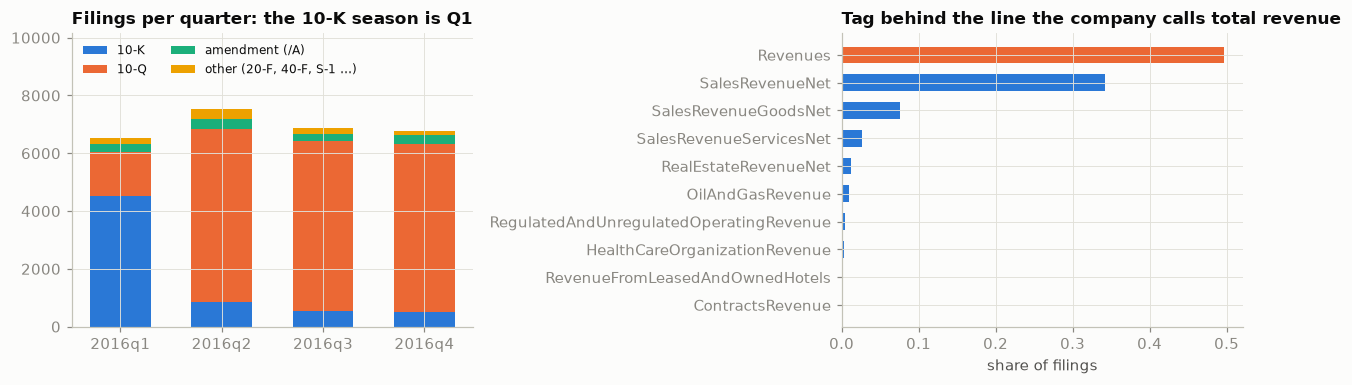

In [5]:
# Which tag carries the line a company itself calls total revenue?
REV_LABEL = (r"^(total )?(net )?(operating )?(revenues?|sales)( net)?$|^(total )?(net )?(revenues?|sales),? net$"
             r"|^total (net )?(operating )?(revenues?|sales)$|^net sales and (operating )?revenues?$|^sales and (other )?revenues?$")
con.execute(r"CREATE MACRO norm_label(s) AS trim(regexp_replace(regexp_replace(lower(coalesce(s, '')), '[^a-z, ]', ' ', 'g'), '\s+', ' ', 'g'))")
con.execute(f"""CREATE TEMP TABLE rev_lines AS
   SELECT s.adsh, s.cik, s.form, s.fy, s.fp, s.period, s.fsq, p.tag, p.custom, p.plabel, n.qtrs, n.value
   FROM pre p JOIN sub s USING (adsh)
   JOIN num n ON n.adsh = p.adsh AND n.tag = p.tag AND n.version = p.version AND n.ddate = s.period AND n.coreg IS NULL AND n.uom = 'USD'
   WHERE p.stmt = 'IS' AND p.inpth = 0 AND s.form IN ('10-K', '10-Q') AND regexp_matches(norm_label(p.plabel), '{REV_LABEL}')
     AND ((s.form = '10-K' AND n.qtrs = 4) OR (s.form = '10-Q' AND n.qtrs = 1))""")
rev_one = con.execute("""SELECT * FROM rev_lines WHERE adsh IN (SELECT adsh FROM rev_lines GROUP BY adsh HAVING count(DISTINCT value) = 1)
                         QUALIFY row_number() OVER (PARTITION BY adsh ORDER BY tag) = 1""").df()
n_k = (sub.form == "10-K").sum()
top_tags = rev_one.assign(tag=rev_one.tag.where(~rev_one.custom, "(a custom tag)")).tag.value_counts()
print(f"filings with exactly one line labelled as total revenue: {len(rev_one):,} "
      f"({(rev_one.form == '10-K').sum():,} of {n_k:,} 10-Ks) · distinct tags behind that line: {rev_one.tag.nunique():,}")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6))
ax = axes[0]
bottom = np.zeros(len(form_mix))
for i, c in enumerate(form_mix.columns):
    ax.bar(form_mix.index, form_mix[c], bottom=bottom, color=SERIES[i], width=0.6, label=c); bottom += form_mix[c].values
ax.set_ylim(0, form_mix.sum(axis=1).max() * 1.35)
ax.set_title("Filings per quarter: the 10-K season is Q1"); ax.legend(fontsize=8, ncol=2, loc="upper left")
ax = axes[1]
show = top_tags.head(10)[::-1]
ax.barh(show.index, show.values / len(rev_one), color=[SERIES[1] if t == "Revenues" else SERIES[0] for t in show.index], height=0.6)
ax.set_title("Tag behind the line the company calls total revenue"); ax.set_xlabel("share of filings")
plt.tight_layout()

Left: 4,518 10-Ks arrive in Q1, then the 10-Q season, so the question mix shifts through the year. Right: quirk 1; mapping *revenue* to `Revenues` misses half the market.

# Part B — The given model

*Sections 3–6: read them, then package the code unchanged and reproduce its numbers (C2). You do not change the method.*

## 3 · The knowledge layer: concepts, calculation checks and a custom-tag mapper

*Part B · Given model · package the concept table, `identity_check` and the mapper unchanged; E3 adds its review loop.*

Session 07 starts from competency questions; here, the analysts': revenue, net income, operating cash flow, assets, liabilities, equity and cash, for a company or an industry. The taxonomy supplies concepts; which tags count as each, in what order, is your ADR. The Revenue members were read off this year's Figure 1, so the knowledge layer is in-sample for this golden set; S3 tests it on 2017.

In [6]:
CONCEPTS = {   # the team's knowledge base: concept → (analyst phrases, member tags in precedence order, period type)
    "Revenue":    (["revenue", "revenues", "net sales", "sales", "turnover", "top line"],
                   ["Revenues", "SalesRevenueNet", "SalesRevenueGoodsNet", "SalesRevenueServicesNet", "RevenuesNetOfInterestExpense",
                    "RealEstateRevenueNet", "OilAndGasRevenue", "RegulatedAndUnregulatedOperatingRevenue", "ElectricUtilityRevenue",
                    "HealthCareOrganizationRevenue", "RevenueMineralSales", "RefiningAndMarketingRevenue", "ContractsRevenue"], "duration"),
    "NetIncome":  (["net income", "net profit", "net earnings", "profit", "earnings", "net loss", "bottom line"],
                   ["NetIncomeLoss", "NetIncomeLossAvailableToCommonStockholdersBasic", "ProfitLoss"], "duration"),
    "OperatingCashFlow": (["operating cash flow", "cash from operations", "cash generated by operations", "cash flow from operating activities"],
                   ["NetCashProvidedByUsedInOperatingActivities", "NetCashProvidedByUsedInOperatingActivitiesContinuingOperations"], "duration"),
    "Assets":     (["total assets", "assets", "balance sheet total"], ["Assets"], "instant"),
    "Liabilities": (["total liabilities", "liabilities"], ["Liabilities"], "instant"),
    "Equity":     (["shareholders equity", "stockholders equity", "shareholders funds", "book value", "equity"],
                   ["StockholdersEquity", "StockholdersEquityIncludingPortionAttributableToNoncontrollingInterest"], "instant"),
    "Cash":       (["cash and cash equivalents", "cash and equivalents", "cash"], ["CashAndCashEquivalentsAtCarryingValue", "Cash"], "instant"),
}
kb_rows = []
for concept, (phrases, tags, ptype) in CONCEPTS.items():
    for rank, t in enumerate(tags):
        kb_rows.append({"concept": concept, "tag": t, "priority": rank, "period_type": ptype})
kb = pd.DataFrame(kb_rows)
con.register("kb_df", kb); con.execute("CREATE TABLE kb AS SELECT * FROM kb_df")
print(f"{len(CONCEPTS)} concepts · {len(kb)} member tags · the first two members of each, with the taxonomy's own label:")
defs = con.execute("""SELECT k.concept, k.tag, any_value(t.tlabel) AS taxonomy_label, any_value(t.crdr) AS balance, any_value(t.iord) AS period
                      FROM kb k LEFT JOIN tag t ON t.tag = k.tag AND t.custom = 0 WHERE k.priority < 2 GROUP BY ALL ORDER BY k.concept, any_value(k.priority)""").df()
display(defs)

7 concepts · 24 member tags · the first two members of each, with the taxonomy's own label:


,concept,tag,taxonomy_label,balance,period
0,Assets,Assets,Assets,D,I
1,Cash,CashAndCashEquivalentsAtCarryingValue,"Cash and Cash Equivalents, at Carrying Value",D,I
2,Cash,Cash,Cash,D,I
3,Equity,StockholdersEquity,Stockholders' Equity Attributable to Parent,C,I
4,Equity,StockholdersEquityIncludingPortionAttributableToNoncontrollingInte...,"Stockholders' Equity, Including Portion Attributable to Noncontrol...",C,I
5,Liabilities,Liabilities,Liabilities,C,I
6,NetIncome,NetIncomeLoss,Net Income (Loss) Attributable to Parent,C,D
7,NetIncome,NetIncomeLossAvailableToCommonStockholdersBasic,"Net Income (Loss) Available to Common Stockholders, Basic",C,D
8,OperatingCashFlow,NetCashProvidedByUsedInOperatingActivities,Net Cash Provided by (Used in) Operating Activities,NaN,D
9,OperatingCashFlow,NetCashProvidedByUsedInOperatingActivitiesContinuingOperations,"Net Cash Provided by (Used in) Operating Activities, Continuing Op...",NaN,D


In [7]:
# Calculation links from the taxonomy, checked on as-filed facts of original filings
IDENTITIES = {
    "Assets = LiabilitiesAndStockholdersEquity":            ("Assets", ["LiabilitiesAndStockholdersEquity"], [], 0),
    "SalesRevenueNet = Goods + Services":                   ("SalesRevenueNet", ["SalesRevenueGoodsNet", "SalesRevenueServicesNet"], [], None),
    "GrossProfit = Revenues − CostOfRevenue":               ("GrossProfit", ["Revenues"], ["CostOfRevenue"], None),
    "ProfitLoss = NetIncomeLoss + NCI share":               ("ProfitLoss", ["NetIncomeLoss", "NetIncomeLossAttributableToNoncontrollingInterest"], [], None),
    "L&SE = Liabilities + StockholdersEquity (ignores NCI, temporary equity)": ("LiabilitiesAndStockholdersEquity", ["Liabilities", "StockholdersEquity"], [], 0),
}
def identity_check(total, plus, minus, qtrs):
    tags = [total] + plus + minus
    w = con.execute(f"""
        SELECT n.adsh, n.ddate, n.qtrs, {', '.join(f"max(CASE WHEN n.tag = '{t}' THEN n.value END) AS \"{t}\"" for t in tags)}
        FROM num n JOIN sub s USING (adsh)
        WHERE n.tag IN ({', '.join(f"'{t}'" for t in tags)}) AND n.coreg IS NULL AND n.uom = 'USD' AND s.form IN ('10-K', '10-Q')
          AND n.ddate = s.period {'' if qtrs is None else f'AND n.qtrs = {qtrs}'}
        GROUP BY ALL""").df().dropna()
    rhs = w[plus].sum(axis=1) - (w[minus].sum(axis=1) if minus else 0)
    ok = (w[total] - rhs).abs() <= np.maximum(1000, 0.005 * w[total].abs())
    return len(w), ok.mean()
ident = pd.DataFrame([(name, *identity_check(*spec)) for name, spec in IDENTITIES.items()], columns=["identity", "contexts checked", "holds"])
display(ident.style.format({"contexts checked": "{:,}", "holds": "{:.2%}"}))

,identity,contexts checked,holds
0,Assets = LiabilitiesAndStockholdersEquity,"24,895",99.96%
1,SalesRevenueNet = Goods + Services,"1,107",84.19%
2,GrossProfit = Revenues − CostOfRevenue,"3,210",95.64%
3,ProfitLoss = NetIncomeLoss + NCI share,"7,292",94.98%
4,"L&SE = Liabilities + StockholdersEquity (ignores NCI, temporary equity)","17,649",82.65%


The balance-sheet identity holds in 99.96 % of 24,895 original-filing contexts, so a failure means a wrong number. The others hold in 83–96 %: a total may have more children than those listed (non-controlling interests, temporary equity), so a failure means *look*, not *wrong*. Task E2 turns these into SHACL shapes.

**Custom tags.** 13.1 % of numbers sit on tags a company invented. Mapping them is what a data vendor sells, with no ground truth. We build a *silver* one: a company reporting the same amount, period and statement under a custom tag in one filing and a standard tag in another (never used in the first) has re-tagged the line. Silver labels are noisy (a component can equal a total): read scores as lower bounds.

In [8]:
t0 = time.time()
def cached_table(name: str, sql: str) -> None:
    '''Pipeline-stage cache: run the SQL once, keep the result as Parquet in PROCESSED, load it as a DuckDB table.'''
    path = PROCESSED / f"08_{name}.parquet"
    if not path.exists():
        con.execute(f"COPY ({sql}) TO '{path}' (FORMAT parquet, COMPRESSION zstd)")
    con.execute(f"CREATE OR REPLACE TABLE {name} AS SELECT * FROM read_parquet('{path}')")

# line items: one row per (filing, tag) on a primary statement, with the filer's own label
cached_table("line_items", """
   SELECT p.adsh, s.cik, s.fsq, p.tag, any_value(p.custom) AS custom, arg_min(p.stmt, p.report::INT * 1000 + p.line) AS stmt,
          norm_label(arg_min(p.plabel, p.report::INT * 1000 + p.line)) AS label
   FROM pre p JOIN sub s USING (adsh) WHERE p.inpth = 0 AND p.stmt IN ('BS', 'IS', 'CF', 'EQ', 'CI') GROUP BY p.adsh, s.cik, s.fsq, p.tag""")
con.execute("CREATE OR REPLACE VIEW li AS SELECT * FROM line_items")
# silver labels: a company re-tagged the same number. Custom tag in filing A, standard tag in another filing B of the same company,
# same statement, same period and duration, same amount, and the standard tag is not used anywhere in filing A.
cached_table("silver", f"""
   WITH cf AS (SELECT l.cik, n.adsh, n.tag, l.stmt, n.ddate, n.qtrs, n.value FROM num n JOIN li l USING (adsh, tag)
               WHERE n.custom AND n.coreg IS NULL AND n.uom = 'USD' AND abs(n.value) >= {MIN_ABS_USD}),
        sf AS (SELECT s.cik, n.adsh, n.tag, n.ddate, n.qtrs, n.value FROM num n JOIN sub s USING (adsh)
               WHERE NOT n.custom AND n.coreg IS NULL AND n.uom = 'USD' AND abs(n.value) >= {MIN_ABS_USD}
                 AND (s.cik, n.ddate, n.qtrs, n.value) IN (SELECT (cik, ddate, qtrs, value) FROM cf)),
        pairs AS (SELECT c.cik, c.adsh, c.tag AS ctag, f.tag AS stag, c.ddate, c.qtrs FROM cf c
                  JOIN sf f ON c.cik = f.cik AND c.ddate = f.ddate AND c.qtrs = f.qtrs AND c.value = f.value AND c.adsh <> f.adsh
                  JOIN li l ON l.adsh = f.adsh AND l.tag = f.tag AND l.stmt = c.stmt),
        clean AS (SELECT p.* FROM pairs p ANTI JOIN li x ON x.adsh = p.adsh AND x.tag = p.stag),
        cand AS (SELECT cik, ctag, stag, count(DISTINCT (ddate, qtrs)) AS n_ctx FROM clean GROUP BY ALL)
   SELECT cik, ctag, any_value(stag) AS stag, max(n_ctx) AS n_ctx FROM cand GROUP BY cik, ctag HAVING count(*) = 1""")
silver = con.execute("""SELECT s.*, l.label, l.stmt, l.fsq FROM silver s JOIN
     (SELECT cik, tag, arg_min(label, fsq) AS label, arg_min(stmt, fsq) AS stmt, min(fsq) AS fsq FROM li WHERE custom GROUP BY 1, 2) l
     ON l.cik = s.cik AND l.tag = s.ctag""").df()
n_custom_items = con.execute("SELECT count(DISTINCT (cik, tag)) FROM li WHERE custom").fetchone()[0]
print(f"{n_custom_items:,} custom line-item tags (company × tag) · {len(silver):,} with a silver label from re-tagging "
      f"({silver.cik.nunique():,} companies, {silver.stag.nunique():,} distinct standard targets) · {time.time()-t0:.0f}s")
display(silver.sample(6, random_state=SEED)[["ctag", "label", "stmt", "stag"]])

100,244 custom line-item tags (company × tag) · 1,420 with a silver label from re-tagging (972 companies, 691 distinct standard targets) · 2s


,ctag,label,stmt,stag
1156,ManagementFeesPayable,management fees,BS,ManagementFeePayable
950,AccruedOfficerSalary,accrued officer salary,BS,AccruedSalariesCurrent
251,SharesIssuedForRelatedPartyLiabilities,shares issued for related party liabilities,CF,StockIssued1
158,OtherMinorityInterestsIncludingJointVentures,other consolidated entities,BS,OtherMinorityInterests
614,ShareSubscriptionsPayable,share subscriptions payable,BS,CommonStockSharesSubscriptions
572,IntangiblesAndOtherAssetsNet,"intangible and other, net",BS,OtherAssets


**The mapper** adds two TF-IDF nearest-neighbour signals: the custom tag's name and label against the taxonomy's names and labels, and its label against the labels other filers wrote next to each standard tag. Candidates must have appeared on the same statement. Evaluation is **split by company**: half the companies with silver labels are held out and the index holds only other filers' line items. Top-1 is the right tag first; top-5 is the list a reviewer would see.

In [9]:
STMTS = ["BS", "IS", "CF", "EQ", "CI"]
split_camel = lambda t: re.sub(r"([a-z0-9])([A-Z])", r"\1 \2", re.sub(r"([A-Z]+)([A-Z][a-z])", r"\1 \2", t)).lower()
std_labels = con.execute("SELECT tag, any_value(tlabel) AS tlabel FROM tag WHERE custom = 0 GROUP BY tag").df().set_index("tag").tlabel

# one vocabulary for every mapper below: the labels filers used for standard tags, plus the taxonomy's names and labels
std_pairs = con.execute("SELECT tag, label FROM li WHERE NOT custom GROUP BY tag, label ORDER BY tag, label").df().reset_index(names="pid")
con.execute("CREATE OR REPLACE TABLE std_pairs AS SELECT * FROM std_pairs")
ALL_TAGS = pd.Index(sorted(std_pairs.tag.unique()))
tax_text = [split_camel(c) + " " + str(std_labels.get(c, "") or "").lower() for c in ALL_TAGS]
VEC = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, dtype=np.float32).fit(list(std_pairs.label) + tax_text)
M_ALL, C_ALL = normalize(VEC.transform(std_pairs.label)), normalize(VEC.transform(tax_text))

class TagMapper:
    '''Suggest standard US-GAAP tags for a custom tag. Two TF-IDF nearest-neighbour signals: (a) the taxonomy's tag names and
    labels, (b) the line labels other filers used with each standard tag; candidates restricted to tags seen on the same statement.
    `where` decides whose standard line items the index may contain: that is the train/test split.'''
    def __init__(self, where="TRUE"):
        ids = con.execute(f"""SELECT DISTINCT p.pid FROM li JOIN std_pairs p USING (tag, label)
                              WHERE NOT li.custom AND {where} ORDER BY 1""").df().pid.values
        on = con.execute(f"SELECT DISTINCT tag, stmt FROM li WHERE NOT custom AND {where}").df()
        tags_sub = std_pairs.tag.values[ids]
        self.classes = pd.Index(sorted(set(tags_sub))); cl = {c: i for i, c in enumerate(self.classes)}
        on = on[on.tag.isin(cl)]
        self.on_stmt = np.zeros((len(STMTS), len(self.classes)), bool)
        self.on_stmt[on.stmt.map(STMTS.index).values, on.tag.map(cl).values] = True
        self.M, self.C = M_ALL[ids], C_ALL[ALL_TAGS.get_indexer(self.classes)]
        self.pair_cls, self.n_pairs = pd.Series(tags_sub).map(cl).values, len(ids)
    def components(self, ctag, label, stmt):
        T = (normalize(VEC.transform(pd.Series(ctag).map(split_camel) + " " + pd.Series(label))) @ self.C.T).toarray()
        K = np.zeros_like(T)
        Q = normalize(VEC.transform(label))
        for a in range(0, len(label), 100):                         # max similarity to any label another filer used for the tag
            R = (Q[a:a + 100] @ self.M.T).tocsr()
            rows = np.repeat(np.arange(R.shape[0]), np.diff(R.indptr))
            np.maximum.at(K[a:a + 100], (rows, self.pair_cls[R.indices]), R.data)
        return T, K, self.on_stmt[pd.Series(stmt).map(STMTS.index).values]
    def suggest(self, df, k=5, use=("taxonomy", "labels"), chunk=1000):
        out_s, out_v = [], []
        for a in range(0, len(df), chunk):
            d = df.iloc[a:a + chunk]
            T, K, mask = self.components(d.ctag.values, d.label.values, d.stmt.values)
            S = np.where(mask, ("taxonomy" in use) * T + ("labels" in use) * K, -1)
            top = np.argsort(-S, axis=1)[:, :k]
            out_s += [list(self.classes[r]) for r in top]; out_v.append(np.take_along_axis(S, top, axis=1))
        return out_s, np.vstack(out_v)

VARIANTS = {"taxonomy names and labels only": ("taxonomy",), "other filers' line labels only": ("labels",),
            "both (the baseline mapper)": ("taxonomy", "labels")}
def evaluate(mapper, test, variants=VARIANTS):
    T, K, mask = mapper.components(test.ctag.values, test.label.values, test.stmt.values)
    y = test.stag.map({c: i for i, c in enumerate(mapper.classes)}).fillna(-1).values[:, None]
    out = {}
    for name, use in variants.items():
        top = np.argsort(-np.where(mask, ("taxonomy" in use) * T + ("labels" in use) * K, -1), axis=1)[:, :5]
        out[name] = {"top-1": (top[:, :1] == y).any(1).mean(), "top-5": (top == y).any(1).mean(), "test tags": len(test)}
    return pd.DataFrame(out).T

def ci95(k, n):
    '''Two-sided 95 % Clopper–Pearson interval for k successes out of n.'''
    return (beta.ppf(0.025, k, n - k + 1) if k > 0 else 0.0), (beta.ppf(0.975, k + 1, n - k) if k < n else 1.0)

ciks = np.array(sorted(silver.cik.unique()))
test_ciks = set(rng.choice(ciks, len(ciks) // 2, replace=False))
test_co = silver[silver.cik.isin(test_ciks)].reset_index(drop=True)
not_test = f"cik NOT IN ({','.join(map(str, sorted(test_ciks)))})"
t0 = time.time()
mapper_co = TagMapper(where=not_test)
res_map = evaluate(mapper_co, test_co)
print(f"split by company: {len(test_ciks):,} of the {len(ciks):,} companies with silver labels are held out; the mapper indexes "
      f"{mapper_co.n_pairs:,} (tag, label) pairs from every other filer's standard line items · {len(mapper_co.classes):,} candidate tags · {time.time()-t0:.0f}s")
display(res_map.style.format({"top-1": "{:.1%}", "top-5": "{:.1%}", "test tags": "{:,.0f}"}))
MAP_TOP5 = res_map.loc["both (the baseline mapper)", "top-5"]
MAP_CI = ci95(round(MAP_TOP5 * len(test_co)), len(test_co))
print(f"baseline mapper top-5 {MAP_TOP5:.1%}, 95 % interval {MAP_CI[0]:.1%}–{MAP_CI[1]:.1%}")

split by company: 486 of the 972 companies with silver labels are held out; the mapper indexes 270,660 (tag, label) pairs from every other filer's standard line items · 6,067 candidate tags · 7s


,top-1,top-5,test tags
taxonomy names and labels only,22.5%,43.7%,702
other filers' line labels only,21.9%,49.4%,702
both (the baseline mapper),32.3%,60.5%,702


baseline mapper top-5 60.5%, 95 % interval 56.8%–64.2%


Combined, the signals rank the right tag first for 32.3 % of unseen companies' custom tags and in the top five for 60.5 % (95 % interval 56.8–64.2 %), out of 6,067 candidates: a reviewer's suggestion list, not an automatic mapping. Trap 6 shows how it could have been reported as 83 %.

## 4 · Plain-English questions → SQL, and a golden set to hold it to

*Part B · Given model · package `parse`, `build_sql`, `answer` and `verify` unchanged; reproduce the ladder (C2); E1 redoes its ablation.*

Task 04's lesson, on a warehouse: a question naming a company, a concept and a period is a lookup. The parser is deterministic (gazetteer, patterns, phrases), with one SQL template per intent. What matters is the **golden set**: questions generated from the data, answered by code that shares no SQL with the service (pandas over the Parquet; revenue lines from Section 2's label query). Three conventions define "correct", each an ADR:

- **as filed**: the value in the original 10-K or 10-Q for that period (not an amendment or a later comparative), parent only, in US dollars;
- **fiscal year**: the SEC's `fy` field on the 10-K;
- **revenue**: the line the company itself labels total revenue, whatever its tag.

In [10]:
# ---- the golden set: built from the data, answered by an independent pandas implementation (no SQL) -------------
def as_filed(tags):
    '''Independent path: read the sorted Parquet with a pyarrow filter, keep original 10-K/10-Q filings and the filing's own period.'''
    df = pd.concat([pd.read_parquet(f, columns=["adsh", "tag", "coreg", "ddate", "qtrs", "uom", "value"], filters=[("tag", "in", tags)])
                    for f in files("num")])
    df = df[df.coreg.isna() & (df.uom == "USD") & df.value.notna()].merge(sub[["adsh", "cik", "name", "sic", "form", "fy", "fp", "period", "filed", "fye"]], on="adsh")
    df = df[df.form.isin(["10-K", "10-Q"]) & (df.ddate == df.period)]
    return df.sort_values("filed").drop_duplicates(["cik", "tag", "form", "period", "qtrs"])

SUFFIX = r"\b(inc|incorporated|corp|corporation|co|company|ltd|limited|llc|l l c|lp|l p|plc|n v|s a|the)\b"
def norm_name(n: str) -> str:
    n = re.sub(r"/[a-z]{2,3}/?$|\\[a-z]{2,3}\\?$", "", n.lower().strip())            # EDGAR state suffixes such as /DE/
    return re.sub(r"\s+", " ", re.sub(SUFFIX, " ", re.sub(r"[^a-z0-9 ]", " ", n))).strip()
names = sub.drop_duplicates("cik")[["cik", "name"]].assign(key=lambda d: d.name.map(norm_name))
key_ciks = names.groupby("key").cik.apply(lambda s: sorted(set(s)))
GAZ = {k: v for k, v in key_ciks.items() if len(k) >= 4}
KEY_OF = dict(zip(names.cik, names.key))
display_name = lambda cik: KEY_OF[cik].title()
UNIQUE = {c for c, k in KEY_OF.items() if len(GAZ.get(k, [])) == 1}
unique_key = lambda cik: cik in UNIQUE
print(f"{len(names):,} filers · {len(key_ciks):,} normalised names · {(key_ciks.map(len) > 1).sum():,} names shared by several CIKs")

MONTHS = ["january", "february", "march", "april", "may", "june", "july", "august", "september", "october", "november", "december"]
fmt_date = lambda d, style: (f"{d.day} {MONTHS[d.month-1].title()} {d.year}" if style == 0 else f"{d:%Y-%m-%d}")
PHRASE = {"Revenue": ["revenue", "net sales", "sales", "turnover"], "NetIncome": ["net income", "net profit", "earnings"],
          "OperatingCashFlow": ["operating cash flow", "cash from operations"], "Assets": ["total assets"], "Liabilities": ["total liabilities"],
          "Equity": ["shareholders' equity", "stockholders' equity", "book value"], "Cash": ["cash and cash equivalents", "cash"]}
DEV = {   # phrasings the parser rules were written against
    "point":   ["What were {co}'s {c} at {d}?", "{co} {c} as of {d}?"],
    "fiscal":  ["What was {co}'s {c} in fiscal {fy}?", "{co} {c} for fiscal year {fy}?"],
    "quarter": ["What was {co}'s {c} for the quarter ended {d}?", "{co} {c} in the three months to {d}?"],
    "count":   ["How many SIC {sic} companies reported a net loss for fiscal {fy}?"],
    "sum":     ["What were the combined total assets of SIC {sic} companies at {d}?"],
    "rank":    ["Which SIC {sic} company had the largest total assets at {d}?"],
}
HELD_OUT = {   # written with the development phrasings, before any run, and never used to tune the parser
    "point":   ["Can you pull {co}'s {c} on the {d} balance sheet?", "As at {d}, how much were {co}'s {c}?"],
    "fiscal":  ["Give me {c} for {co}, FY{fy}.", "How much {c} did {co} book in its {fy} fiscal year?"],
    "quarter": ["{co}: {c}, quarter ending {d}?", "What {c} did {co} post in the quarter to {d}?"],
    "count":   ["Number of loss-making SIC {sic} firms in fiscal {fy}?"],
    "sum":     ["Sum of total assets across SIC {sic} filers as of {d}?"],
    "rank":    ["Biggest SIC {sic} company by total assets at {d}?"],
}

7,229 filers · 7,204 normalised names · 24 names shared by several CIKs


Six families: **point** (a balance-sheet figure on a date), **fiscal** (a full-year flow, half for non-December year ends), **quarter**, and **count**, **sum** and **rank** across an industry (SIC code). Seven revenue questions concern custom-tagged revenue lines, where the mapper can change a headline answer. Each question also gets a **held-out phrasing**, written with the development ones but never used to tune the parser.

In [11]:
gold_rows = []
pick = lambda df, n: df.sample(min(n, len(df)), random_state=SEED)
def add(family, concept, row, answer, **slots):
    gold_rows.append({"family": family, "concept": concept, "answer": answer, **slots, "cik": row.get("cik"), "fye": row.get("fye")})

facts_bs = as_filed(["Assets", "Liabilities", "StockholdersEquity", "CashAndCashEquivalentsAtCarryingValue"])
for concept, tag in [("Assets", "Assets"), ("Liabilities", "Liabilities"), ("Equity", "StockholdersEquity"), ("Cash", "CashAndCashEquivalentsAtCarryingValue")]:
    f = facts_bs[(facts_bs.tag == tag) & (facts_bs.qtrs == 0)]
    f = f[f.cik.map(unique_key)].drop_duplicates(["cik", "period"])           # one as-filed value per company and date
    for r in pick(f, N_PER_CELL).to_dict("records"):
        add("point", concept, r, r["value"], d=r["period"], answer_tag=tag)
facts_fl = as_filed(["NetIncomeLoss", "NetCashProvidedByUsedInOperatingActivities"])
rev = rev_one[~rev_one.custom].merge(sub[["adsh", "name", "sic", "filed", "fye"]], on="adsh")
for concept, f in [("Revenue", rev.rename(columns={})), ("NetIncome", facts_fl[facts_fl.tag == "NetIncomeLoss"]),
                   ("OperatingCashFlow", facts_fl[facts_fl.tag == "NetCashProvidedByUsedInOperatingActivities"])]:
    f = f[f.cik.map(unique_key)]
    k = f[(f.form == "10-K") & (f.fp == "FY") & (f.qtrs == 4)].drop_duplicates(["cik", "fy"])
    k = k[k.fy.isin([2015, 2016])]
    k = pd.concat([pick(k[k.fye == "1231"], N_PER_CELL // 2), pick(k[k.fye != "1231"], N_PER_CELL - N_PER_CELL // 2)])   # stratified: non-December year ends
    for r in k.to_dict("records"):
        add("fiscal", concept, r, r["value"], fy=r["fy"], answer_tag=r["tag"])
    if concept in ("Revenue", "NetIncome"):
        qq = f[(f.form == "10-Q") & (f.qtrs == 1)].drop_duplicates(["cik", "period"])
        for r in pick(qq, N_PER_CELL).to_dict("records"):
            add("quarter", concept, r, r["value"], d=r["period"], answer_tag=r["tag"])
# custom-tagged top lines: the only place the tag mapper can change a headline answer
rev_custom = rev_one[rev_one.custom].merge(sub[["adsh", "name", "sic", "filed", "fye"]], on="adsh")
rev_custom = rev_custom[rev_custom.cik.map(unique_key)].drop_duplicates("cik")
for r in rev_custom.to_dict("records"):
    if r["form"] == "10-K": add("fiscal", "Revenue (custom tag)", r, r["value"], fy=r["fy"], answer_tag=r["tag"])
    else:                   add("quarter", "Revenue (custom tag)", r, r["value"], d=r["period"], answer_tag=r["tag"])
# cross-company questions: one as-filed value per company
ni_tags = CONCEPTS["NetIncome"][1]                               # convention (ADR): the first net-income tag the 10-K reports
loss = as_filed(ni_tags).query("form == '10-K' and fp == 'FY' and qtrs == 4")
loss = loss.assign(rank=loss.tag.map(ni_tags.index)).sort_values(["rank", "filed"]).drop_duplicates(["cik", "fy"])
sics = loss[loss.fy == 2015].groupby("sic").cik.nunique()
for sic in pick(sics[sics >= 15].reset_index(), N_PER_CELL).sic:
    g = loss[(loss.sic == sic) & (loss.fy == 2015)]
    add("count", "NetIncome", {}, int((g.value < 0).sum()), sic=int(sic), fy=2015)
assets = facts_bs[(facts_bs.tag == "Assets") & (facts_bs.qtrs == 0)].drop_duplicates(["cik", "period"])
cells = assets.groupby(["sic", "period"]).cik.nunique()
cells = cells[cells >= 8].reset_index()
for r in pick(cells, N_PER_CELL).to_dict("records"):
    g = assets[(assets.sic == r["sic"]) & (assets.period == r["period"])]
    add("sum", "Assets", {}, float(g.value.sum()), sic=int(r["sic"]), d=r["period"])
for r in pick(cells.sample(frac=1, random_state=1), N_PER_CELL).to_dict("records"):
    g = assets[(assets.sic == r["sic"]) & (assets.period == r["period"])]
    add("rank", "Assets", {}, int(g.sort_values(["value", "cik"], ascending=[False, True]).cik.iloc[0]), sic=int(r["sic"]), d=r["period"])   # ties: lowest CIK

gold = pd.DataFrame(gold_rows)
def phrase(row, templates, i):
    c = PHRASE[row.concept.split(" (")[0]][i % len(PHRASE[row.concept.split(" (")[0]])] if row.family in ("point", "fiscal", "quarter") else ""
    co = display_name(row.cik) if row.family in ("point", "fiscal", "quarter") else ""
    t = templates[row.family][i % len(templates[row.family])]
    d, fy, sic = getattr(row, "d", None), getattr(row, "fy", None), getattr(row, "sic", None)
    return t.format(co=co, c=c, d=fmt_date(pd.Timestamp(d), i % 2) if pd.notna(d) else "",
                    fy=int(fy) if pd.notna(fy) else "", sic=int(sic) if pd.notna(sic) else "")
gold["question"] = [phrase(r, DEV, i) for i, r in enumerate(gold.itertuples())]
gold["held_out"] = [phrase(r, HELD_OUT, i) for i, r in enumerate(gold.itertuples())]
GOLD_SHA256 = hashlib.sha256(gold[["family", "concept", "question", "held_out", "answer"]].to_csv(index=False).encode()).hexdigest()
print(f"{len(gold)} golden questions · {gold.groupby('family').size().to_dict()} · {(gold.concept == 'Revenue (custom tag)').sum()} on custom-tagged "
      f"revenue lines · fingerprint sha256:{GOLD_SHA256[:16]}…")
display(gold.sample(6, random_state=SEED)[["family", "concept", "question", "answer"]])

151 golden questions · {'count': 12, 'fiscal': 40, 'point': 48, 'quarter': 27, 'rank': 12, 'sum': 12} · 7 on custom-tagged revenue lines · fingerprint sha256:0c4d749d61487864…


,family,concept,question,answer
133,sum,Assets,What were the combined total assets of SIC 2835 companies at 2016-...,9.985318e+09
104,fiscal,OperatingCashFlow,What was Steris's operating cash flow in fiscal 2015?,2.546750e+08
128,sum,Assets,What were the combined total assets of SIC 1311 companies at 30 Ju...,4.986396e+11
97,fiscal,OperatingCashFlow,Sterling Bancorp cash from operations for fiscal year 2015?,9.175600e+07
148,rank,Assets,Which SIC 7372 company had the largest total assets at 30 April 2016?,1.108524e+06
120,count,NetIncome,How many SIC 7374 companies reported a net loss for fiscal 2015?,4.900000e+01


**The parser.** Only the concept step differs between routes: with the **raw schema** it sees what a schema-only prompt would show (the 500 most used tag names) and picks the closest by word overlap; with **taxonomy context** it uses the concept table. Shared names are asked back.

In [12]:
# ---- the parser: deterministic query understanding ---------------------------------------------------------------
top_tags_schema = con.execute("SELECT tag, count(*) AS n FROM num WHERE NOT custom GROUP BY tag ORDER BY n DESC LIMIT 500").df()
SCHEMA_TAGS = [(t, set(split_camel(t).split())) for t in top_tags_schema.tag]        # what a raw-schema prompt would show
PHRASE_TO_CONCEPT = sorted(((p, c) for c, (ps, _, _) in CONCEPTS.items() for p in ps), key=lambda x: -len(x[0]))
STOP = set("what were was is are the of at as on in for to did does how much many which company companies had have has report reported "
           "a an its their fiscal year quarter ended ending three months sic combined largest highest biggest can you pull give me book "
           "post balance sheet number sum across filers firms and by".split())

def qnorm(q):
    return " " + re.sub(r"\s+", " ", re.sub(r"[^a-z0-9\- ]", " ", q.lower().replace("'s ", " ").replace("’s ", " "))) + " "

def parse_period(ql):
    if m := re.search(r"\b(20\d\d)-(\d\d)-(\d\d)\b", ql):
        return "date", pd.Timestamp(int(m.group(1)), int(m.group(2)), int(m.group(3)))
    if m := re.search(r"\b(\d{1,2}) (" + "|".join(MONTHS) + r") (20\d\d)\b", ql):
        return "date", pd.Timestamp(int(m.group(3)), MONTHS.index(m.group(2)) + 1, int(m.group(1)))
    if m := re.search(r"\b(?:fiscal(?: year)?|fy) ?(20\d\d)\b", ql):
        return "fy", int(m.group(1))
    return None, None

def raw_schema_tag(words):
    '''Raw schema only: pick the schema tag whose CamelCase words best overlap the question's content words.'''
    stem = lambda w: w[:-1] if w.endswith("s") and len(w) > 3 else w
    ws = {stem(w) for w in words}
    best = max(SCHEMA_TAGS, key=lambda t: (len(ws & {stem(x) for x in t[1]}), -len(t[1])))   # ties: the shorter tag
    return [best[0]] if ws & {stem(x) for x in best[1]} else []

def parse(q: str, kb_context=True) -> dict:
    ql = qnorm(q)
    out = {"status": "ok"}
    if m := re.search(r"\bsic (\d{4})\b", ql): out["sic"] = int(m.group(1))
    ptype, pval = parse_period(ql)
    if ptype: out[ptype] = pval
    hits = [k for k in GAZ if f" {k} " in ql]
    if hits:
        k = max(hits, key=len); out["ciks"] = GAZ[k]; ql_rest = ql.replace(f" {k} ", " ")
    else:
        ql_rest = ql
    if kb_context:
        c = next((c for p, c in PHRASE_TO_CONCEPT if f" {p} " in ql_rest), None)
        if "loss" in ql_rest and "sic" in out: c = "NetIncome"
        out["concept"], out["tags"] = c, (CONCEPTS[c][1] if c else [])
    else:
        words = [w for w in re.sub(r"\d", " ", ql_rest).split() if w not in STOP and len(w) > 2]
        out["concept"], out["tags"] = "raw", raw_schema_tag(words)
    if "how many" in ql or "number of" in ql: out["intent"] = "count"
    elif any(w in ql for w in (" combined ", " sum of ", " total across ")): out["intent"] = "sum"
    elif any(w in ql for w in (" which ", " biggest ", " largest ")) and "sic" in out: out["intent"] = "rank"
    elif any(w in ql for w in (" quarter ", " three months ")) and "date" in out: out["intent"] = "quarter"
    elif "fy" in out: out["intent"] = "fiscal"
    elif "date" in out: out["intent"] = "point"
    else: return {"status": "not understood"}
    if out["intent"] in ("point", "fiscal", "quarter"):
        if "ciks" not in out: return {"status": "unknown company"}
        if len(out["ciks"]) > 1: return {"status": "ambiguous company", "candidates": out["ciks"]}
    elif "sic" not in out:
        return {"status": "not understood"}
    if not out["tags"]: return {"status": "unknown concept"}
    return out

for q in [gold.question.iloc[0], gold[gold.family == "fiscal"].question.iloc[0], gold[gold.family == "count"].question.iloc[0]]:
    print(f"{q!r:75s} → kb: {({k: v for k, v in parse(q).items() if k != 'tags'})}")
    print(f"{'':75s}   raw: {parse(q, kb_context=False)}")

"What were Dupont E I De Nemours's total assets at 31 December 2015?"       → kb: {'status': 'ok', 'date': Timestamp('2015-12-31 00:00:00'), 'ciks': [30554], 'concept': 'Assets', 'intent': 'point'}
                                                                              raw: {'status': 'ok', 'date': Timestamp('2015-12-31 00:00:00'), 'ciks': [30554], 'concept': 'raw', 'tags': ['Assets'], 'intent': 'point'}
"What was Birner Dental Management Services's revenue in fiscal 2015?"      → kb: {'status': 'ok', 'fy': 2015, 'ciks': [948072], 'concept': 'Revenue', 'intent': 'fiscal'}
                                                                              raw: {'status': 'ok', 'fy': 2015, 'ciks': [948072], 'concept': 'raw', 'tags': ['Revenues'], 'intent': 'fiscal'}
'How many SIC 7389 companies reported a net loss for fiscal 2015?'          → kb: {'status': 'ok', 'sic': 7389, 'fy': 2015, 'concept': 'NetIncome', 'intent': 'count'}
                                                          

**The ladder.** The same parser and templates run five times; each rung adds one piece of context: raw schema (R0), taxonomy concepts (R1), the as-filed rule (R2), the fiscal-year convention (R3), the custom-tag mapper (R4). R1 against R0 is the knowledge-base ablation; the later rungs price the conventions.

In [13]:
# ---- SQL templates, one per intent; each rung of the ladder adds one piece of context -----------------------------
RUNGS = ["R0 raw schema", "R1 + taxonomy concepts", "R2 + as-filed rule", "R3 + fiscal-year convention", "R4 + custom-tag mapper"]

def build_sql(p, rung, original_only=False):
    kb, asfiled, fiscal, mapper = rung >= 1, rung >= 2, rung >= 3, rung >= 4
    original = asfiled or original_only          # the original-filing rule alone (Trap 2) or as part of the as-filed rule
    tags = p["tags"]
    tag_in = ", ".join(f"'{t}'" for t in tags)
    prio = "CASE n.tag " + " ".join(f"WHEN '{t}' THEN {i}" for i, t in enumerate(tags)) + " ELSE 99 END"
    tag_filter = f"n.tag IN ({tag_in})"
    if mapper and p["intent"] in ("point", "fiscal", "quarter"):        # add the company's custom tags the mapper sends to a member tag
        mapped = con.execute(f"""SELECT DISTINCT m.adsh, m.ctag FROM custom_map m JOIN sub s USING (adsh)
                                 WHERE s.cik = {p['ciks'][0]} AND m.stag IN ({tag_in})""").fetchall()
        if mapped:
            names_in = ", ".join(sorted({f"'{t}'" for _, t in mapped}))
            pairs_in = ", ".join(f"('{a}', '{t}')" for a, t in mapped)
            tag_filter = f"n.tag IN ({tag_in}, {names_in}) AND (n.tag IN ({tag_in}) OR (n.custom AND (n.adsh, n.tag) IN ({pairs_in})))"
            prio = prio.replace("ELSE 99", "ELSE 50")
    filt = ((" AND s.form IN ('10-K', '10-Q') AND n.ddate = s.period" if original else "")
            + (" AND n.coreg IS NULL AND n.uom = 'USD' AND n.value IS NOT NULL" if asfiled else ""))
    q_inst = " AND n.qtrs = 0" if asfiled else ""
    if p["intent"] == "fiscal":
        period = (f"s.fy = {p['fy']} AND s.fp = 'FY' AND s.form = '10-K'" if fiscal else f"year(n.ddate) = {p['fy']}") + " AND n.qtrs = 4"
    elif p["intent"] == "quarter":
        period = f"n.ddate = DATE '{p['date']:%Y-%m-%d}'" + (" AND n.qtrs = 1 AND s.form = '10-Q'" if asfiled else "")
    elif p["intent"] in ("point", "sum", "rank"):
        period = f"n.ddate = DATE '{p['date']:%Y-%m-%d}'" + q_inst
    else:  # count
        period = (f"s.fy = {p['fy']} AND s.fp = 'FY' AND s.form = '10-K'" if fiscal else f"year(n.ddate) = {p['fy']}") + " AND n.qtrs = 4"
    base = f"FROM num n JOIN sub s USING (adsh) WHERE {tag_filter} AND {period}{filt}"
    order = f"ORDER BY {prio}, s.filed, n.adsh" if kb else "ORDER BY n.adsh"
    if p["intent"] in ("point", "fiscal", "quarter"):
        return f"SELECT n.value, n.adsh, n.tag, n.ddate, n.qtrs, s.form, s.filed {base} AND s.cik = {p['ciks'][0]} {order} LIMIT 1"
    if not original:   # naive aggregates: one row per fact
        if p["intent"] == "rank":
            return f"SELECT s.cik {base} AND s.sic = {p['sic']} AND n.value IS NOT NULL ORDER BY n.value DESC, s.cik LIMIT 1"
        agg = {"count": "count(*) FILTER (WHERE n.value < 0)", "sum": "sum(n.value)"}[p["intent"]]
        return f"SELECT {agg} {base} AND s.sic = {p['sic']}"
    one = f"SELECT s.cik, arg_min(n.value, {prio} * 1e10 + epoch(s.filed)) AS value {base} AND s.sic = {p['sic']} GROUP BY s.cik"
    if p["intent"] == "rank":
        return f"SELECT cik FROM ({one}) ORDER BY value DESC, cik LIMIT 1"
    agg = {"count": "count(*) FILTER (WHERE value < 0)", "sum": "sum(value)"}[p["intent"]]
    return f"SELECT {agg} FROM ({one})"

@lru_cache(maxsize=None)
def run_sql(sql):
    return con.execute(sql).fetchall()

def answer(q, rung, original_only=False):
    p = parse(q, kb_context=rung >= 1)
    if p["status"] != "ok":
        return {"status": p["status"], "value": None, "sql": None}
    sql = build_sql(p, rung, original_only)
    rows = run_sql(sql)
    row = rows[0] if rows else None
    if row is None or row[0] is None:
        return {"status": "no rows", "value": None, "sql": sql}
    return {"status": "answered", "value": row[0], "sql": sql, "provenance": row[1:] if len(row) > 1 else None}

def correct(a, g):
    if a is None: return False
    return abs(float(a) - float(g)) <= max(0.5, 1e-6 * abs(float(g)))

In [14]:
# custom-tag mapper, applied to every custom line item on the income statements of the filings the golden questions touch
mapper_all = TagMapper()                                      # production mapper: every filer's standard line items
gold_ciks = ",".join(str(int(c)) for c in gold.cik.dropna().unique())
cust_is = con.execute(f"SELECT adsh, tag AS ctag, label, stmt FROM li WHERE custom AND stmt = 'IS' AND cik IN ({gold_ciks})").df()
sugg, sc = mapper_all.suggest(cust_is, k=1)
cust_is["stag"], cust_is["score"] = [s[0] for s in sugg], sc[:, 0]
con.register("custom_map_df", cust_is); con.execute("CREATE OR REPLACE TABLE custom_map AS SELECT * FROM custom_map_df")
print(f"custom income-statement line items mapped: {len(cust_is):,} · mapped to a revenue member tag: "
      f"{cust_is.stag.isin(CONCEPTS['Revenue'][1]).sum():,}")

t0 = time.time()
runs = []
for r in gold.itertuples():
    for rung in range(len(RUNGS)):
        a = answer(r.question, rung)
        runs.append({"i": r.Index, "family": r.family, "concept": r.concept, "rung": RUNGS[rung], "status": a["status"],
                     "correct": correct(a["value"], r.answer)})
runs = pd.DataFrame(runs)
ladder = runs.pivot_table(index="family", columns="rung", values="correct", aggfunc="mean")[RUNGS]
ladder.loc["all questions"] = runs.groupby("rung").correct.mean()[RUNGS]
n_ok = int(runs[runs.rung == RUNGS[-1]].correct.sum())
EXEC_CI = ci95(n_ok, len(gold))
print(f"{len(runs):,} SQL executions in {time.time()-t0:.0f}s · {RUNGS[-1]}: {n_ok} of {len(gold)} correct, "
      f"95 % interval {EXEC_CI[0]:.1%}–{EXEC_CI[1]:.1%}")
display(ladder.style.format("{:.1%}").background_gradient(cmap="Blues", axis=None, vmin=0, vmax=1))

custom income-statement line items mapped: 754 · mapped to a revenue member tag: 37


755 SQL executions in 25s · R4 + custom-tag mapper: 147 of 151 correct, 95 % interval 93.4%–99.3%


rung,R0 raw schema,R1 + taxonomy concepts,R2 + as-filed rule,R3 + fiscal-year convention,R4 + custom-tag mapper
family,,,,,
count,0.0%,0.0%,25.0%,100.0%,100.0%
fiscal,17.5%,70.0%,75.0%,90.0%,95.0%
point,66.7%,95.8%,100.0%,100.0%,100.0%
quarter,18.5%,51.9%,85.2%,85.2%,92.6%
rank,100.0%,100.0%,100.0%,100.0%,100.0%
sum,8.3%,8.3%,100.0%,100.0%,100.0%
all questions,37.7%,66.9%,84.8%,94.7%,97.4%


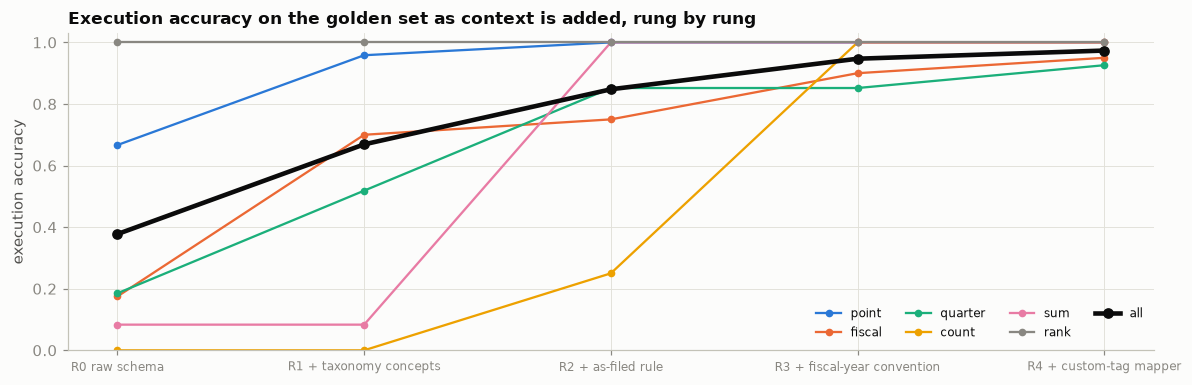

In [15]:
fig, ax = plt.subplots(figsize=(11, 3.6))
fams = ["point", "fiscal", "quarter", "count", "sum", "rank"]
x = np.arange(len(RUNGS))
for i, f in enumerate(fams):
    ax.plot(x, ladder.loc[f].values, "-o", ms=4, lw=1.5, color=SERIES[i % len(SERIES)] if i < 5 else MUTED, label=f)
ax.plot(x, ladder.loc["all questions"].values, "-o", ms=6, lw=3, color=INK, label="all")
ax.set_xticks(x); ax.set_xticklabels(RUNGS, fontsize=8); ax.set_ylim(0, 1.03); ax.set_ylabel("execution accuracy")
ax.set_title("Execution accuracy on the golden set as context is added, rung by rung"); ax.legend(fontsize=8, ncol=4, loc="lower right")
plt.tight_layout()

The raw schema answers 37.7 % (it finds `Assets` but not *book value*, and sends *revenue* to `Revenues`); taxonomy concepts lift it to 66.9 %. The as-filed rule adds 18 points where the naive query returned *a* number (a comparative, a co-registrant, a year-to-date figure); sums go from 8 % to 100 %, counts from 0 % to 25 %. The fiscal-year convention fixes non-December companies and takes counts to 100 %, and the mapper adds custom-tagged revenue: 147 of 151, 97.4 % (95 % interval 93.4–99.3 %).

In [16]:
# held-out phrasings and the refusal profile of the final route
final = RUNGS[-1]
held = []
for r in gold.itertuples():
    a = answer(r.held_out, len(RUNGS) - 1)
    held.append({"family": r.family, "status": a["status"], "correct": correct(a["value"], r.answer)})
held = pd.DataFrame(held)
fin = runs[runs.rung == final]
outcome = lambda d: pd.Series({"correct": d.correct.mean(), "wrong number": ((d.status == "answered") & ~d.correct).mean(),
                               "refused or not understood": (d.status != "answered").mean()})
prof = pd.DataFrame({"development phrasings": outcome(fin), "held-out phrasings": outcome(held)}).T
display(prof.style.format("{:.1%}"))
print("held-out failures by parser status:", held[~held.correct].status.value_counts().to_dict())

,correct,wrong number,refused or not understood
development phrasings,97.4%,1.3%,1.3%
held-out phrasings,84.8%,1.3%,13.9%


held-out failures by parser status: {'not understood': 19, 'no rows': 2, 'answered': 2}


On held-out phrasings accuracy falls to 84.8 %, mostly questions the parser does not understand (*"in its 2015 fiscal year"*); wrong numbers stay at 1.3 %. Refusing is the right failure, and the parser (or S1's LLM) needs test questions written by someone else.

**Trust.** Every answer carries its provenance (accession number, form, filing date, tag, period, duration), and `verify` re-runs the SQL and recomputes the number from the rows before it is shown. S1 keeps this contract for LLM-written SQL, whose structured output must fill `ANSWER_SCHEMA`.

In [17]:
# Trust: every answer carries the rows it came from. The GenAI stretch keeps this contract.
ANSWER_SCHEMA = {"type": "object", "required": ["intent", "concept", "company_cik", "period", "sql"],
                 "properties": {"intent": {"enum": ["point", "fiscal", "quarter", "count", "sum", "rank"]},
                                "concept": {"enum": list(CONCEPTS)}, "company_cik": {"type": ["integer", "null"]},
                                "period": {"type": "string"}, "sql": {"type": "string"}, "refuse_reason": {"type": ["string", "null"]}}}

def verify(sql: str, claimed: float) -> dict:
    '''Re-run the query, recompute the number from the returned rows, and only then show it (S1 keeps this for LLM-written SQL).'''
    rows = con.execute(sql).fetchall()
    recomputed = rows[0][0] if rows else None
    return {"rows": len(rows), "recomputed": recomputed, "shown": recomputed if recomputed is not None and correct(claimed, recomputed) else None}

ex = gold[gold.family == "fiscal"].iloc[0]
a = answer(ex.question, len(RUNGS) - 1)
print(ex.question)
print(f"  answer {a['value']:,.0f} USD · from filing {a['provenance'][0]} ({a['provenance'][4]}, filed {a['provenance'][5]}) · tag {a['provenance'][1]} · "
      f"period ending {a['provenance'][2]}, {a['provenance'][3]} quarters · verify → {verify(a['sql'], a['value'])}")
print("  structured output an LLM would have to return:", json.dumps(ANSWER_SCHEMA)[:160], "…")

What was Birner Dental Management Services's revenue in fiscal 2015?
  answer 63,843,837 USD · from filing 0001140361-16-059508 (10-K, filed 2016-03-30) · tag Revenues · period ending 2015-12-31, 4 quarters · verify → {'rows': 1, 'recomputed': 63843837.0, 'shown': 63843837.0}
  structured output an LLM would have to return: {"type": "object", "required": ["intent", "concept", "company_cik", "period", "sql"], "properties": {"intent": {"enum": ["point", "fiscal", "quarter", "count",  …


## 5 · The traps ⚠

*Part B · Given model · read; C1 turns each trap into a test.*

Six ways a careless service produces a confident, wrong number, each measured naive against honest.

**Trap 1 — the same concept under many tags.** A schema-only route sends *revenue* to `Revenues`, the tag on half the revenue lines.

In [18]:
# Trap 1 — the same concept under many tags
rev_q = runs[(runs.concept == "Revenue")]
t1 = rev_q.pivot_table(index="concept", columns="rung", values="correct", aggfunc="mean")[RUNGS[:2]]
print(f"top-line revenue lines tagged 'Revenues': {top_tags.get('Revenues', 0)/len(rev_one):.1%} of {len(rev_one):,} filings · "
      f"revenue questions answered correctly · raw schema {t1.iloc[0, 0]:.0%} · with taxonomy concepts {t1.iloc[0, 1]:.0%}")

top-line revenue lines tagged 'Revenues': 49.6% of 17,291 filings · revenue questions answered correctly · raw schema 25% · with taxonomy concepts 71%


Revenue questions: 25 % right with the raw schema, 71 % with taxonomy concepts; the rest closes only with the conventions below.

**Trap 2 — amendments and restatements.** The same fact (company, tag, date, duration) in several filings: how often does its value change?

In [19]:
# Trap 2 — amendments and restatements: one fact, several values
restated = con.execute("""
  WITH f AS (SELECT s.cik, n.tag, n.ddate, n.qtrs, n.value, s.form, s.filed, s.period FROM num n JOIN sub s USING (adsh)
             WHERE NOT n.custom AND n.coreg IS NULL AND n.uom = 'USD' AND n.tag IN ('Assets', 'Liabilities', 'StockholdersEquity', 'NetIncomeLoss', 'Revenues', 'SalesRevenueNet')),
       g AS (SELECT cik, tag, ddate, qtrs, count(*) n, count(DISTINCT value) nv,
                    arg_min(value, filed) AS first_value, arg_max(value, filed) AS last_value FROM f GROUP BY ALL HAVING count(*) > 1)
  SELECT tag, count(*) AS facts_reported_twice_or_more, avg((nv > 1)::INT) AS share_with_different_values,
         median(abs(last_value - first_value) / nullif(abs(first_value), 0)) FILTER (WHERE nv > 1) AS median_rel_change
  FROM g GROUP BY tag ORDER BY 2 DESC""").df()
display(restated.style.format({"facts_reported_twice_or_more": "{:,}", "share_with_different_values": "{:.1%}", "median_rel_change": "{:.2%}"}))
# the original-filing rule on its own: R1 plus "the original 10-K/10-Q for that period, earliest filed", nothing else
iso = pd.DataFrame([{"family": r.family, "R1 + taxonomy concepts": correct(answer(r.question, 1)["value"], r.answer),
                     "R1 + original-filing rule only": correct(answer(r.question, 1, original_only=True)["value"], r.answer),
                     "R2 + as-filed rule": correct(answer(r.question, 2)["value"], r.answer)} for r in gold.itertuples()])
iso_t = iso.groupby("family").mean(); iso_t.loc["all questions"] = iso.drop(columns="family").mean()
display(iso_t.style.format("{:.1%}"))
amend = sub[sub.form.isin(["10-K/A", "10-Q/A"])]
print(f"amendments in the window: {len(amend):,} ({len(amend)/len(sub):.1%} of filings) · original filings later amended (prevrpt = 1): {int(sub.prevrpt.sum()):,}")

,tag,facts_reported_twice_or_more,share_with_different_values,median_rel_change
0,NetIncomeLoss,"12,855",9.5%,2.88%
1,StockholdersEquity,"9,203",5.7%,1.64%
2,Assets,"8,529",22.5%,0.37%
3,Liabilities,"6,584",22.1%,0.62%
4,Revenues,"5,751",7.9%,5.45%
5,SalesRevenueNet,"4,400",8.9%,3.96%


,R1 + taxonomy concepts,R1 + original-filing rule only,R2 + as-filed rule
family,,,
count,0.0%,25.0%,25.0%
fiscal,70.0%,70.0%,75.0%
point,95.8%,95.8%,100.0%
quarter,51.9%,51.9%,85.2%
rank,100.0%,91.7%,100.0%
sum,8.3%,41.7%,100.0%
all questions,66.9%,70.9%,84.8%


amendments in the window: 883 (3.2% of filings) · original filings later amended (prevrpt = 1): 674


Of `Assets` and `Liabilities` facts reported more than once, 22 % change value (median 0.4–0.6 %); net income, 9.5 % (median 2.9 %). Pick one by rule, say which, flag restatements. Alone, the original-filing rule lifts R1 from 66.9 % to 70.9 % (sums 8 → 42 %, counts 0 → 25 %, rankings down to 92 %); the parent, dollar and duration filters (Traps 3, 5) supply the rest of R2's 84.8 %.

**Trap 3 — units and scale.** Other currencies share the dollar column, and some restatements differ by exactly ×1,000 or ×1,000,000, the signature of a scale error.

In [20]:
# Trap 3 — units and scale
units = con.execute("""SELECT uom, count(*) AS facts, count(DISTINCT adsh) AS filings FROM num
                       WHERE tag IN ('Revenues', 'SalesRevenueNet') AND qtrs = 4 GROUP BY uom ORDER BY facts DESC LIMIT 6""").df()
naive_total, usd_total = con.execute("""SELECT sum(value), sum(value) FILTER (WHERE uom = 'USD') FROM num n JOIN sub s USING (adsh)
     WHERE n.tag = 'Revenues' AND n.qtrs = 4 AND n.coreg IS NULL AND s.form IN ('10-K', '20-F', '40-F') AND n.ddate = s.period""").fetchone()
scale = con.execute(f"""
  WITH f AS (SELECT s.cik, n.tag, n.ddate, n.qtrs, n.value FROM num n JOIN sub s USING (adsh)
             WHERE NOT n.custom AND n.coreg IS NULL AND n.uom = 'USD' AND abs(n.value) >= 1000
               AND n.tag IN ({', '.join(repr(t) for t in top_tags_schema.tag[:100])})),
       g AS (SELECT cik, tag, ddate, qtrs, min(abs(value)) lo, max(abs(value)) hi FROM f GROUP BY ALL HAVING count(DISTINCT value) > 1)
  SELECT count(*) FILTER (WHERE hi / lo BETWEEN 999 AND 1001 OR hi / lo BETWEEN 999000 AND 1001000) AS x1000, count(*) AS restated_facts,
         count(DISTINCT cik) FILTER (WHERE hi / lo BETWEEN 999 AND 1001 OR hi / lo BETWEEN 999000 AND 1001000) AS companies,
         count(*) FILTER (WHERE hi = lo * 1000 OR hi = lo * 1000000) AS exact FROM g""").fetchone()
display(units)
print(f"sum of 'Revenues' over annual reports, all units {naive_total/1e12:,.1f} tn vs USD only {usd_total/1e12:,.1f} tn "
      f"(×{naive_total/usd_total:.1f}) · facts restated by ×1,000 or ×1,000,000 (within 0.1 %): {scale[0]:,} of {scale[1]:,} restated facts "
      f"at {scale[2]:,} companies, {scale[3]:,} of them exactly")

,uom,facts,filings
0,USD,20041,5707
1,CNY,137,33
2,JPY,61,14
3,CAD,60,15
4,CHF,12,1
5,EUR,12,5


sum of 'Revenues' over annual reports, all units 75.0 tn vs USD only 8.5 tn (×8.8) · facts restated by ×1,000 or ×1,000,000 (within 0.1 %): 154 of 23,837 restated facts at 24 companies, 118 of them exactly


Summing `Revenues` over annual reports without a unit filter gives 75.0 trillion against 8.5 trillion in dollars (×8.8: other currencies counted as dollars). ×1,000 restatements are rare (154 of 23,837 restated facts on the 100 commonest tags, at 24 companies, 118 exact), but each is a thousand-fold error somewhere. Filter on `uom`; alert on scale jumps.

**Trap 4 — fiscal against calendar years.** "Fiscal 2015" read as `year(ddate) = 2015` against the SEC's `fy` field.

In [21]:
# Trap 4 — fiscal against calendar years
k10 = sub[sub.form == "10-K"]
fy_off = (k10.fy != k10.period.dt.year)
fisc = runs[runs.family == "fiscal"].merge(gold[["fye"]], left_on="i", right_index=True)
fisc["year_end"] = np.where(fisc.fye.fillna("1231") == "1231", "31 December", "other year end")
t4 = fisc[fisc.rung.isin(RUNGS[2:4])].groupby(["year_end", "rung"]).correct.agg(["sum", "count"])
t4 = t4.apply(lambda r: f"{int(r['sum'])} / {int(r['count'])} ({r['sum'] / r['count']:.0%})", axis=1).unstack("rung")[RUNGS[2:4]]
jm = k10.period.dt.month <= 3
print(f"10-Ks whose fiscal-year field differs from the calendar year of the period end: {fy_off.sum():,} of {len(k10):,} ({fy_off.mean():.1%}) · "
      f"January–March year ends with fy = year − 1: {(jm & (k10.fy == k10.period.dt.year - 1)).sum():,} of {jm.sum():,} · "
      f"other mismatches: {(fy_off & ~jm).sum():,}")
display(t4)

10-Ks whose fiscal-year field differs from the calendar year of the period end: 467 of 6,382 (7.3%) · January–March year ends with fy = year − 1: 466 of 469 · other mismatches: 1


rung,R2 + as-filed rule,R3 + fiscal-year convention
year_end,,
31 December,18 / 20 (90%),18 / 20 (90%)
other year end,12 / 20 (60%),18 / 20 (90%)


December year ends: 18 of 20 either way; other year ends: 12 of 20 calendar, 18 of 20 with `fy`. Small samples, but the mechanism is plain: a retailer's fiscal 2015 ends in January 2016, so the calendar query finds nothing or the wrong year. The answer must state its period end.

**Trap 5 — duplicated facts.** An industry sum or count over rows, not companies, counts comparatives, co-registrants, amendments and durations several times, and groups where parent and subsidiary both file.

In [22]:
# Trap 5 — duplicated facts across filings, durations and co-registrants
agg_q = runs[runs.family.isin(["sum", "count"])]
naive_vs = []
for r in gold[gold.family.isin(["sum", "count"])].itertuples():
    naive = answer(r.question, 1)["value"]; honest = answer(r.question, 3)["value"]
    naive_vs.append({"family": r.family, "ratio": (naive or 0) / r.answer if r.answer else np.nan, "honest_ok": correct(honest, r.answer)})
naive_vs = pd.DataFrame(naive_vs)
coreg_share = con.execute("SELECT avg((coreg IS NOT NULL)::INT) FROM num WHERE tag = 'Assets'").fetchone()[0]
twins = con.execute("""WITH a AS (SELECT DISTINCT s.cik, s.name, n.ddate, n.value FROM num n JOIN sub s USING (adsh) WHERE n.tag = 'Assets' AND n.qtrs = 0
                       AND n.coreg IS NULL AND n.uom = 'USD' AND n.value >= 1e8 AND s.form IN ('10-K', '10-Q') AND n.ddate = s.period)
                       SELECT x.name AS a, y.name AS b, split_part(lower(x.name), ' ', 1) = split_part(lower(y.name), ' ', 1) AS same_group
                       FROM a x JOIN a y ON x.ddate = y.ddate AND x.value = y.value AND x.cik < y.cik""").df()
dur = con.execute("""SELECT count(*) FROM (SELECT n.adsh FROM num n JOIN sub s USING (adsh) WHERE s.form = '10-Q' AND n.tag = 'NetIncomeLoss'
                     AND n.ddate = s.period AND n.coreg IS NULL GROUP BY n.adsh HAVING count(DISTINCT n.qtrs) > 1)""").fetchone()[0]
print(f"naive aggregate ÷ honest answer · sums: median ×{naive_vs[naive_vs.family == 'sum'].ratio.median():.2f} · counts: median ×{naive_vs[naive_vs.family == 'count'].ratio.median():.2f}")
print(f"'Assets' facts belonging to a co-registrant: {coreg_share:.1%} · 10-Qs reporting net income for two durations at the same date: {dur:,} · "
      f"pairs of filers reporting identical total assets (≥ $100 m) on the same date: {len(twins)}, of which {twins.same_group.sum()} share the first word "
      f"of their names, e.g. {', '.join(twins[twins.same_group].drop_duplicates('a').head(3).apply(lambda r: f'{r.a.title()} / {r.b.title()}', axis=1))}")

naive aggregate ÷ honest answer · sums: median ×1.72 · counts: median ×3.29
'Assets' facts belonging to a co-registrant: 20.4% · 10-Qs reporting net income for two durations at the same date: 11,365 · pairs of filers reporting identical total assets (≥ $100 m) on the same date: 56, of which 19 share the first word of their names, e.g. Vornado Realty Trust / Vornado Realty Lp, Mack Cali Realty Corp / Mack Cali Realty L P, Simon Property Group L P /De/ / Simon Property Group Inc /De/


Naive sums come out at a median ×1.72 the honest answer and naive counts at ×3.29, with no error raised. Co-registrants hold 20.4 % of `Assets` facts; 11,365 10-Qs report net income for two durations at one date. Identical total assets at two filers are partly coincidence, partly groups filing twice: sums need an entity rule (C1).

**Trap 6 — the leaky evaluation of the tag mapper.** Let the index include the test companies' own standard line items, as a random split by filing would.

In [23]:
# Trap 6 — the leaky evaluation of the tag mapper
t0 = time.time()
both = {"both": VARIANTS["both (the baseline mapper)"]}
leaky = evaluate(mapper_all, test_co, both).loc["both"]          # index includes the test companies' own standard line items
honest = res_map.loc["both (the baseline mapper)"]
print(f"mapper top-1 / top-5 on the same {len(test_co):,} custom tags · index includes their own companies {leaky['top-1']:.1%} / {leaky['top-5']:.1%} · "
      f"other companies only {honest['top-1']:.1%} / {honest['top-5']:.1%} · {time.time()-t0:.0f}s")

mapper top-1 / top-5 on the same 702 custom tags · index includes their own companies 54.7% / 82.9% · other companies only 32.3% / 60.5% · 3s


Same tags: 54.7 % top-1 and 82.9 % top-5 with the test companies' own filings in the index, 32.3 % and 60.5 % without. Companies re-use their labels, so a split by filing measures memory.

## 6 · The operating point: answer, verify or refer

*Part B · Given model · package `signals` and `policy`; C3 asks you to own the costs and referral rules.*

Two assumed costs compete (task C3): an analyst answer (20 minutes at €70 an hour, €23) and a wrong number in a research note or credit memo (€2,000); analysts are assumed never wrong, which flatters them. Three signals need no gold: a mapper-chosen custom tag; member tags in the filing that disagree (both refer the question); a later restatement (flagged). Policies are costed at the observed wrong rate and its one-sided 95 % upper bound.

break-even wrong rate among shown answers: 1.17% (an analyst answer costs €23) · shown answers needed to prove it with zero errors: 256
wrong answers that pass verification:


,phrasing,question,golden,golden tag,service,service tag
114,question,What was Futurefuel's sales for the quarter ended 30 September 2016?,66893000.0,SalesRevenueNetExcludingRevenueFromRelatedParties,69306000.0,SalesRevenueGoodsNet
265,held_out,"Futurefuel: sales, quarter ending 30 September 2016?",66893000.0,SalesRevenueNetExcludingRevenueFromRelatedParties,69306000.0,SalesRevenueGoodsNet


answers carrying a restatement flag: 10 of 279 · wrong answers by source: {'conflicting members': 2, 'parser/other': 2}


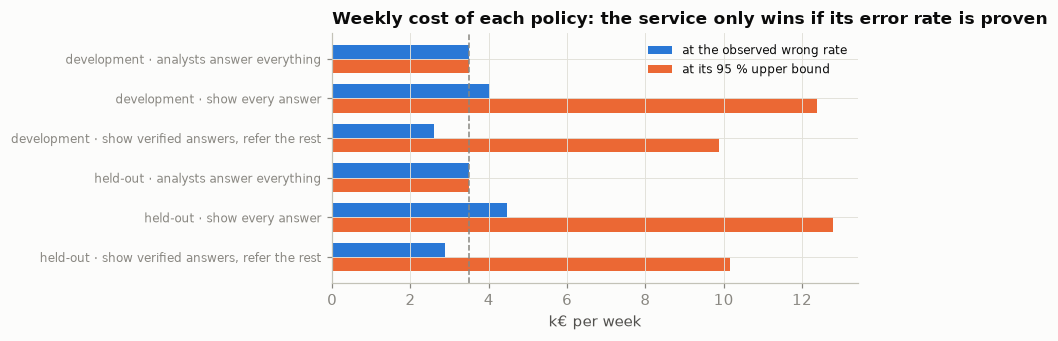

In [24]:
# Verification signals available without the gold: where did the number come from, and does anything disagree with it?
def signals(q):
    p, a = parse(q), answer(q, len(RUNGS) - 1)
    out = {"answered": a["status"] == "answered", "via_mapper": False, "single_candidate": True, "restated": False}
    if not out["answered"] or p["intent"] not in ("point", "fiscal", "quarter"):
        return out
    adsh, tag, ddate, qtrs = a["provenance"][:4]
    rows = run_sql(a["sql"].replace(" LIMIT 1", ""))
    n_vals = run_sql(f"""SELECT count(DISTINCT n.value) FROM num n JOIN sub s USING (adsh) WHERE n.tag = '{tag}' AND s.cik = {p['ciks'][0]}
                         AND n.ddate = DATE '{ddate}' AND n.qtrs = {qtrs} AND n.coreg IS NULL AND n.uom = 'USD'""")[0][0]
    out.update(via_mapper=tag not in CONCEPTS[p["concept"]][1],                  # the number sits on a custom tag the mapper chose
               single_candidate=len({r[0] for r in rows if r[1] == adsh}) <= 1,   # other member tags in the same filing agree
               restated=n_vals > 1)                                              # a later filing reports a different value
    return out

ops = []
for phrasing in ["question", "held_out"]:
    for r in gold.itertuples():
        q = getattr(r, phrasing)
        a = answer(q, len(RUNGS) - 1)
        ops.append({"phrasing": phrasing, "family": r.family, **signals(q), "correct": correct(a["value"], r.answer), "question": q,
                    "golden": r.answer, "golden tag": r.answer_tag, "service": a["value"], "service tag": (a.get("provenance") or [None, None])[1]})
ops = pd.DataFrame(ops)
ops["verified"] = ops.answered & ~ops.via_mapper & ops.single_candidate
analyst_eur = ANALYST_MIN_PER_QUESTION / 60 * ANALYST_COST_PER_HOUR_EUR
def policy(d, show):
    n_shown, n_wrong, referred = int(show.sum()), int((show & ~d.correct).sum()), (~show).mean()
    p_hat = n_wrong / n_shown if n_shown else 0.0
    p_up = beta.ppf(0.95, n_wrong + 1, n_shown - n_wrong) if n_shown else 0.0     # one-sided 95 % upper bound (Clopper–Pearson)
    cost = lambda p: QUESTIONS_PER_WEEK * (show.mean() * p * WRONG_NUMBER_COST_EUR + referred * analyst_eur)
    return {"shown": show.mean(), "referred": referred, "wrong / shown": f"{n_wrong} / {n_shown}", "wrong rate": p_hat,
            "95% upper": p_up, "€ per week": cost(p_hat), "€ per week at the upper bound": cost(p_up)}
pol = {}
for phrasing, d in ops.groupby("phrasing", sort=False):
    d = d.reset_index(drop=True)
    for name, show in [("analysts answer everything", pd.Series(False, index=d.index)), ("show every answer", d.answered),
                       ("show verified answers, refer the rest", d.verified)]:
        pol[(phrasing.replace("question", "development").replace("held_out", "held-out"), name)] = policy(d, show)
pol = pd.DataFrame(pol).T
display(pol.style.format({"shown": "{:.0%}", "referred": "{:.0%}", "wrong rate": "{:.1%}", "95% upper": "{:.1%}",
                          "€ per week": "€{:,.0f}", "€ per week at the upper bound": "€{:,.0f}"}))
p_star = analyst_eur / WRONG_NUMBER_COST_EUR
print(f"break-even wrong rate among shown answers: {p_star:.2%} (an analyst answer costs €{analyst_eur:.0f}) · shown answers needed to prove it "
      f"with zero errors: {int(np.ceil(np.log(0.05) / np.log(1 - p_star))):,}")
print("wrong answers that pass verification:")
display(ops[ops.verified & ~ops.correct][["phrasing", "question", "golden", "golden tag", "service", "service tag"]])
print(f"answers carrying a restatement flag: {(ops.answered & ops.restated).sum()} of {ops.answered.sum()} · "
      f"wrong answers by source: {ops[ops.answered & ~ops.correct].assign(src=lambda d: np.where(d.via_mapper, 'mapper', np.where(d.single_candidate, 'parser/other', 'conflicting members'))).src.value_counts().to_dict()}")

fig, ax = plt.subplots(figsize=(8, 3.2))
labels = [f"{a} · {b}" for a, b in pol.index]
y = np.arange(len(labels))[::-1]
ax.barh(y + 0.18, pol["€ per week"] / 1e3, height=0.36, color=SERIES[0], label="at the observed wrong rate")
ax.barh(y - 0.18, pol["€ per week at the upper bound"] / 1e3, height=0.36, color=SERIES[1], label="at its 95 % upper bound")
ax.axvline(pol["€ per week"].iloc[0] / 1e3, color=MUTED, ls="--", lw=1)
ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=8); ax.legend(fontsize=8)
ax.set_xlabel("k€ per week"); ax.set_title("Weekly cost of each policy: the service only wins if its error rate is proven")
plt.tight_layout()

Showing every answer costs more than the desk (€4,020 against €3,500 a week): 2 wrong in 149 is above break-even. Showing verified answers refers 17 % and leaves 1 wrong in 125, at €2,589, 26 % below the desk. That one is FutureFuel, whose golden line is labelled *Revenue* but tagged as excluding related-party sales: arguably the golden rule is wrong, so golden sets need review too (C3). At the upper bound no policy wins: 151 questions cannot *prove* a rate below the 1.17 % break-even, which takes 256 clean answers. Recommendation: verified answers as drafts an analyst confirms until a larger reviewed golden set clears break-even.

# Part C — Productionise it

*Sections 7–10: this is your assignment.*

## 7 · After deployment: new filers, new tags, a new taxonomy

*Part C · Productionise · what your monitoring plan must catch (C5): new filers, new tags, a new taxonomy.*

Freeze the concept table and mapper after Q1 and let the year run. Three things move outside the service's control: who files, which custom tags they invent, which taxonomy release they use. Q1 is the reference, so all of it counts as new.

,filers,new_filers,custom_tag_names,new_custom_names,share us-gaap/2014,share us-gaap/2015,share us-gaap/2016
fsq,,,,,,,
2016q1,6011,6011,52136,52136,0.118,0.879,0.003
2016q2,6493,904,42950,15065,0.050,0.721,0.230
2016q3,6288,172,39634,6918,0.000,0.357,0.643
2016q4,6191,142,41051,6133,0.000,0.199,0.801


,test tags,frozen after Q1 top-5 (95 % interval),refreshed top-5 (95 % interval),"frozen, own companies indexed (leaky)"
quarter,,,,
2016q1,357,64.1% (59%–69%),64.1% (59%–69%),65.0%
2016q2,190,60.0% (53%–67%),58.4% (51%–66%),73.7%
2016q3,85,61.2% (50%–72%),62.4% (51%–73%),70.6%
2016q4,70,52.9% (41%–65%),52.9% (41%–65%),75.7%


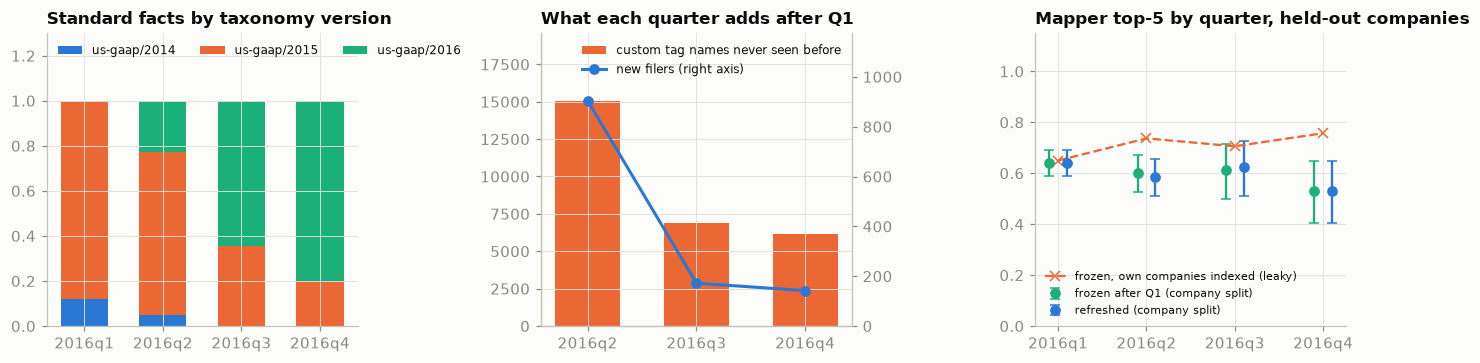

In [25]:
drift = con.execute("""
  WITH f AS (SELECT s.fsq, s.cik, MIN(s.fsq) OVER (PARTITION BY s.cik) AS first_q FROM sub s),
       filers AS (SELECT fsq, count(DISTINCT cik) AS filers, count(DISTINCT cik) FILTER (WHERE fsq = first_q) AS new_filers FROM f GROUP BY fsq),
       ct AS (SELECT fsq, cik, tag, MIN(fsq) OVER (PARTITION BY tag) AS first_any FROM li WHERE custom),
       tags AS (SELECT fsq, count(DISTINCT tag) AS custom_tag_names, count(DISTINCT tag) FILTER (WHERE fsq = first_any) AS new_custom_names FROM ct GROUP BY fsq)
  SELECT * FROM filers JOIN tags USING (fsq) ORDER BY fsq""").df().set_index("fsq")
tax = con.execute("""SELECT fsq, version, count(*) AS n FROM num WHERE NOT custom AND version LIKE 'us-gaap/%' GROUP BY ALL""").df()
tax_share = tax.pivot_table(index="fsq", columns="version", values="n", aggfunc="sum").fillna(0)
tax_share = tax_share.div(tax_share.sum(axis=1), axis=0)
display(drift.join(tax_share.add_prefix("share ").round(3)))

# The mapper over time, like for like with Section 3: the held-out companies never enter the index. Each quarter's test set is
# their custom tags first seen that quarter. "Frozen" indexes Q1 only; "refreshed" indexes every quarter up to the one tested.
fit_where = f"fsq IN ({', '.join(repr(q) for q in MAPPER_FIT_QUARTERS)})"
frozen = TagMapper(where=f"{fit_where} AND {not_test}")
frozen_leaky = TagMapper(where=fit_where)                         # Trap 6 again: the test companies' own Q1 filings in the index
by_q = []
for q in QUARTERS:
    tq = test_co[test_co.fsq == q].reset_index(drop=True)
    refreshed = frozen if q in MAPPER_FIT_QUARTERS else (mapper_co if q == QUARTERS[-1] else TagMapper(where=f"fsq <= '{q}' AND {not_test}"))
    row = {"quarter": q, "test tags": len(tq)}
    for name, m in [("frozen after Q1", frozen), ("refreshed", refreshed), ("frozen, own companies indexed (leaky)", frozen_leaky)]:
        t5 = evaluate(m, tq, both).loc["both", "top-5"]
        row[name], (row[name + " lo"], row[name + " hi"]) = t5, ci95(round(t5 * len(tq)), len(tq))
    by_q.append(row)
by_q = pd.DataFrame(by_q).set_index("quarter")
show = by_q[["test tags"]].copy()
for name in ["frozen after Q1", "refreshed"]:
    show[f"{name} top-5 (95 % interval)"] = [f"{v:.1%} ({a:.0%}–{b:.0%})" for v, a, b in by_q[[name, name + " lo", name + " hi"]].values]
show["frozen, own companies indexed (leaky)"] = by_q["frozen, own companies indexed (leaky)"].map("{:.1%}".format)
display(show)

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.4))
ax = axes[0]
bottom = np.zeros(len(tax_share))
for i, v in enumerate(sorted(tax_share.columns)):
    ax.bar(tax_share.index, tax_share[v], bottom=bottom, color=SERIES[i], width=0.6, label=v); bottom += tax_share[v].values
ax.set_ylim(0, 1.3); ax.set_title("Standard facts by taxonomy version"); ax.legend(fontsize=8, ncol=3, loc="upper left")
ax = axes[1]
later = drift.iloc[1:]                                         # Q1 is the reference: everything in it counts as new
ax.bar(later.index, later.new_custom_names, color=SERIES[1], width=0.6, label="custom tag names never seen before")
ax2 = ax.twinx(); ax2.plot(later.index, later.new_filers, "-o", color=SERIES[0], lw=2, label="new filers (right axis)")
ax2.set_ylim(0, later.new_filers.max() * 1.3); ax2.grid(False); ax2.spines["right"].set_visible(True)
ax.set_ylim(0, later.new_custom_names.max() * 1.3)
ax.set_title("What each quarter adds after Q1")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper right")
ax = axes[2]
x = np.arange(len(by_q))
for off, name, color in [(-0.1, "frozen after Q1", SERIES[2]), (0.1, "refreshed", SERIES[0])]:
    ax.errorbar(x + off, by_q[name], yerr=[by_q[name] - by_q[name + " lo"], by_q[name + " hi"] - by_q[name]], fmt="o", color=color,
                capsize=3, label=f"{name} (company split)")
ax.plot(x, by_q["frozen, own companies indexed (leaky)"], "x--", color=SERIES[1], label="frozen, own companies indexed (leaky)")
ax.set_xticks(x); ax.set_xticklabels(by_q.index); ax.set_ylim(0, 1.15)
ax.set_title("Mapper top-5 by quarter, held-out companies"); ax.legend(fontsize=7, loc="lower left")
plt.tight_layout()

After Q1 come 904 unseen filers, then 172 and 142, and 15,065 new custom tag names, then 6,000–7,000 a quarter; `us-gaap/2016` grows from 0.3 % of standard facts to 80 %. The inputs drift; the mapper does not, measurably. Split by company as in Section 3, the index frozen after Q1 scores like the refreshed one (60.0 against 58.4 % in Q2, 61.2 against 62.4 % in Q3, 52.9 % both in Q4; intervals overlap), so the Q4 dip belongs to that quarter's 70 tags. The leaky line's 71–76 % in Q2–Q4 is memory of the companies' own Q1 labels (Trap 6), not skill. With 70–357 tags a quarter, judge the mapper yearly; re-index quarterly and re-evaluate on each taxonomy release.

## 8 · The module spine for this project

*Part C · Productionise · the targets your system must meet, with this notebook's numbers.*

The CI gate is a golden set, not a validation loss. The card's table, updated:

| Spine | In this project |
|---|---|
| Package and container (S02–S03) | `src/fin_analyst/` (`loader`, `kb`, `parser`, `sql`, `mapper`); `POST /ask` returns value, unit, period, provenance and status (answered, referred, asked back); compose with Postgres, or DuckDB over 126 MB of Parquet a year |
| Monitoring (S04) | Latency, SQL errors, refusals (1.3 % development, 13.9 % held-out), share referred (17 %), restatement flags (10 of 279), identity failures, question mix |
| CI/CD gate (S05) | Gates at the champion's 95 % lower bounds: execution accuracy ≥ 93.4 % (147/151 here), no wrong verified answer, mapper top-5 by company ≥ 56.8 % (60.5 %); refuse if the golden set's SHA-256 changes |
| MLflow tracking and registry (S06) | Concept-table and parser versions, golden-set fingerprint, accuracy per family and rung, wrong-number rate and bound; mapper runs (top-1/top-5 by company); later prompt and LLM |
| Offline / online training and serving | Offline: quarterly load and mapper re-index. Online: one parse and one SQL query per question |
| Data and model drift | Inputs: new filers (904, 172, 142 after Q1), new custom tags (15,065, then 6,000–7,000), `us-gaap/2016` share 0.3 % → 80 %. Mapper: frozen and refreshed indexes alike (53–64 % top-5 by company). Re-index quarterly; trigger: a taxonomy release |
| Knowledge base and context (S07–S09) | 7 concepts, 24 member tags, five calculation links (balance identity 99.96 %). Ablation: raw schema 37.7 % → taxonomy concepts 66.9 % execution accuracy, all else equal; the mapper links custom tags in |
| GenAI and context engineering (S10–S11) | LLM text-to-SQL filling `ANSWER_SCHEMA`, schema-only against concept table in the prompt; `verify` recomputes every number; refuse on shared names (24) and ambiguous concepts |
| Governance | CC0 data; the SEC's disclaimer ("not a substitute for such filings"); not investment advice; contact details dropped; every answer cites its filing |

## 9 · Student tasks

*Part C · Productionise · your assignment.*

This is an individual assignment: you pick one task from the catalogue, claimed first come, first served, so no other student works on it. **The model is given:** you package, evaluate, deploy and monitor this notebook's model; you do not design, tune or replace it. Where a task re-runs training (removing a leaking input, a retraining policy, a knowledge-base ablation), run the notebook's own training code with only its inputs or configuration changed. Work in your own repository, not in this notebook. Promote code into the `src/` package layout from Session 02, keep the notebook as a thin client, and record each design decision as an ADR in `docs/decisions/`. **Required:** all *Core* tasks (C1–C5), all *Extension* tasks (E1–E4) and Stretch **S1**, the GenAI task (Sessions 10–11). No API key is provided: run it on a local open-weight model, with a free hosted tier as an optional comparison, under the data rule for this task in [`docs/llm-access.md`](docs/llm-access.md). The other Stretch tasks are optional and count only towards the top band. The mark rewards the quality of each task, not the number done; the criteria are in `docs/task-rubric.md`.

### Core

- **C1 — Find and fix every trap, with a test each.** The three conventions as ADRs and as SQL tested against an independent implementation; tests that fail when a query drops `qtrs`, `coreg`, `uom` or the original-filing rule; a rule for parent and subsidiary filers in industry sums.
- **C2 — Reproduce and freeze the given model.** Package the notebook's own data loading, features, training and scoring unchanged, retrain from a fresh clone with `SEED`, and show that your pipeline reproduces the numbers listed under *How this notebook is organised* within a tolerance you state. Add a data contract on the raw inputs (schema and value ranges, for example with pandera) and record any difference from the notebook in an ADR. No new features, learners or tuning.
- **C3 — Own the operating point.** Vary `WRONG_NUMBER_COST_EUR` (€200–€20,000), analyst minutes and `QUESTIONS_PER_WEEK`; set the referral rules and the golden-set size that proves break-even, in an ADR the head of research signs. Grow the reviewed golden set towards that size (new families such as growth, ratios and refusals, held-out phrasings written by someone else) without changing the parser, and report the given service's accuracy on it with intervals.
- **C4 — Package and gate.** Move the code into `src/fin_analyst/` with `POST /ask` in a container; `make ci` runs lint, tests and the SHA-256-fingerprinted golden set, gating on the champion's 95 % lower bounds and no wrong verified answer (Sessions 02, 03, 05).
- **C5 — Register, document, monitor.** Versions, golden-set fingerprint and accuracy per family in MLflow; the mapper registered with a `champion` alias and model card; a monitoring plan with Section 7's signals and trigger (Sessions 04, 06).

### Extension

- **E1 — The knowledge-base ablation, done properly.** Derive the concept table from the US-GAAP 2016 linkbases; rerun the ladder (raw schema, hand-written, derived) and report accuracy per family and upkeep (Sessions 07–09).
- **E2 — The taxonomy as a validated graph.** Load concepts, member tags and calculation links into RDF (SKOS for the mapping), write the links as SHACL shapes, and test whether failing filers predict wrong answers.
- **E3 — A review loop for the mapper.** The mapper is given. Route custom tags it maps with low similarity to a reviewer, store accepted mappings as a versioned table in the knowledge layer, and measure how the answers change as the table grows.
- **E4 — Governance note.** The SEC disclaimer, "not investment advice", logging, and your reading of the EU AI Act: Annex III lists creditworthiness assessment of natural persons; does this system ever touch one (sole traders, guarantors)? Phrase it as a question for counsel.

### Stretch

- **S1 — LLM text-to-SQL, verified.** An LLM filling `ANSWER_SCHEMA`, with the raw schema and with the concept table in the prompt; evaluate both on the golden and held-out sets, every number through `verify`; report cost per question and refusals (Sessions 10–11).
- **S2 — Online serving and its cost.** Serve `POST /ask` from Postgres or DuckDB; load-test at 150 questions an hour; report p95 latency and cost per answer with and without an LLM.
- **S3 — The next year.** Load 2017 Q1–Q2 with the 2016 concept table and mapper frozen; measure what breaks and which alert fires first.

## 10 · Hand-in checklist

*Part C · Productionise · tick every box before you submit.*

- [ ] Repository in the Session 02 layout; fresh-clone test passes; `data/` not committed; the loader streams the JSON and drops contact details
- [ ] `README.md` states `QUARTERS`, the three conventions and how to obtain the data (Kaggle, CC0)
- [ ] ADRs for the conventions, the concept table and the referral policy
- [ ] Fingerprinted golden set; accuracy and wrong-number rate per family in CI, with the gate
- [ ] Mapper evaluated by company with a model card; monitoring plan with drift signals and trigger
- [ ] One-page stakeholder recommendation: what it answers, how often it is wrong, what it saves
- [ ] Required tasks done: C1–C5, E1–E4 and S1
- [ ] GenAI task runs on a local model; any hosted run follows the data rule and logs provider, model and cost
- [ ] Reflective diary entry: what you chose, what you rejected, what evidence would change your mind

---

### Appendix — environment and references

- Python ≥ 3.11; `pandas`, `pyarrow`, `duckdb`, `scikit-learn`, `scipy`, `matplotlib`, `kagglehub` (pinned in `requirements.txt`); no LLM.
- U.S. SEC, Division of Economic and Risk Analysis. *Financial Statement Data Sets* (readme in each quarterly file).
- U.S. SEC (2009). *Interactive Data to Improve Financial Reporting*, Release No. 33-9002.
- FASB. *US GAAP Financial Reporting Taxonomy*, 2015 and 2016 releases.
- Yu, T. et al. (2018). *Spider: A Large-Scale Human-Labeled Dataset for … Text-to-SQL Task.* EMNLP.
- Clopper, C. J., Pearson, E. S. (1934). The use of confidence or fiducial limits illustrated in the case of the binomial. *Biometrika* 26(4).

In [26]:
print(f"pandas {pd.__version__} · duckdb {duckdb.__version__} · scikit-learn {sklearn.__version__} · numpy {np.__version__}")
print(f"notebook finished · total wall time {time.time()-T_START:.0f}s")

pandas 3.1.0 · duckdb 2.0.0 · scikit-learn 1.9.1 · numpy 2.5.4
notebook finished · total wall time 103s
